# Does the base model predict which coding tasks can be nudged?

**Panel A of iteration 5, Step 2. Models: Qwen3-8B (instruct, thinking off) and Qwen3-8B-Base.**

Asked for code, Qwen3-8B uses one **default algorithm** almost every time. For "majority element" it writes a
hash-map count in 50 of 50 samples. Earlier iterations found that a small random push can move some tasks off their
default and leaves others pinned. The push is an *isotropic* direction added to the hidden states of the task text
(decoder blocks 12–23, prompt prefill only). This artifact tests a forecast of **which tasks move and where they
land**. The forecast comes from the *base* model and is made before any push:

| | forecast (from Qwen3-8B-Base, on the instruct twin's exact token ids) | outcome (from the pushes) |
|---|---|---|
| **Claim A1: whether a task moves** | $\beta_u$ = share of correct base programs that use a non-default algorithm. The forecast is MOVABLE iff $\beta_u \ge 0.05$ | $E_u$ = share of 8 fixed directions × α ∈ {1, 2} that pass a two-stage binomial escape test |
| **Claim A2: where a pushed task lands** | $r_u$ = most frequent correct non-default base algorithm | $L_u$ = modal algorithm of the confirmed escapes |

Each forecast ($\beta_u$ with its Wilson CI, $r_u$ and the rival predictors) was **sha256-committed** into a hash
chain before the unit's first push row was sampled.

**Published result:** A1 is *not* supported: Spearman ρ(β, E) = −0.03, exact p = 0.56, n = 6 units. The most diverse
unit (count primes, β = 0.81) never escapes, and trivial rivals track E better. A2 *is* supported: on all 3 units
that moved, the base runner-up is exactly where the pushes land (Poisson-binomial p = 0.019). The base composition
also beats AST proximity and association prompting on log score.

### What this notebook runs
`method.py` has four commands: `setup`, `workers`, `unit <A1..A9>` and `final`. The first three need a 24 GB GPU (two
8B models in bf16, ≈1 GPU-hour for 8,620 sampled programs), OpenRouter LLM judges and a code sandbox. This notebook
re-runs the **CPU part of `final`**: the frozen, pre-registered analysis (`src/metrics.py`, `src/escape_rule.py`,
`src/analysis_a1a2.py`, run by `src/final_run.py`), the POST HOC association fix (`src/assoc_fix.py`) and the
hash-chain check (`src/verify_chain.py`). Its input is the artifact's **8,190 labelled programs** (23 units and tasks),
loaded from `mini_demo_data.json`. The code is the artifact's own, split into cells. Every change is marked
`# notebook:` in the code. With the original resampling budgets it runs in one to two minutes on a CPU.

In the language of the wider project ("can we make LLMs give truly creative, non-default solutions?"): the instruct
model gives the *average* answer, and a push can move some tasks away from it. Here we ask whether the base model's
broader repertoire tells you **in advance** which tasks can be moved, and to which alternative.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (the artifact's cfg5.py / final_run.py log with it)
_pip('loguru==0.7.3')

# numpy, scipy, pandas, matplotlib — pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# Original import blocks of method.py, src/cfg5.py, src/commit5.py, src/metrics.py, src/escape_rule.py,
# src/analysis_a1a2.py, src/final_run.py and src/assoc_fix.py, merged. The imports between these modules
# (`from cfg5 import ...`, `import analysis_a1a2 as A`, `from specs5 import SPECS`) are dropped, because all of
# their code lives in this one notebook namespace.
import glob
import hashlib
import itertools
import json
import math
import os
import re
import resource
import shutil
import subprocess
import sys
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Iterable, Sequence

import numpy as np
from loguru import logger
from scipy import stats

# notebook additions: a stand-in for `import analysis_a1a2 as A`, tables and figures
from types import SimpleNamespace

import matplotlib.pyplot as plt
import pandas as pd

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-5/experiment-25/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(f"{data['dataset']}: {data['n_examples']} examples (units / tasks), {data['n_label_rows']} labelled programs")
print("fields kept per labelled program:", data["label_row_fields"])
for ex in data["examples"]:
    print(f"  {ex['task']:4s} {ex['kind']:22s} {ex['n_label_rows']:4d} programs   {ex.get('title', '')}")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
panelA_units: 23 examples (units / tasks), 8190 labelled programs
fields kept per labelled program: ['sample_id', 'arm', 'model', 'slot', 'direction_seed', 'alpha', 'label', 'passed']
  A1   new                     640 programs   majority element
  A2   new                     560 programs   max subarray
  A3   new                     700 programs   trapping rain water
  A4   new                     560 programs   count primes
  A5   new                     560 programs   longest common prefix
  A7   new                     620 programs   longest palindromic substring
  A8   new_reserve_extension   560 programs   jump game
  A9   new_reserve_extension   600 programs   median two sorted
  T03  existing                310 programs   kth smallest
  T10  existing                330 programs   connected components
  T05  existing                210 programs   two sum
  T06  existing                210 progra

## Configuration

The CPU analysis has no training loop. Its only cost knobs are the **resampling budgets** of the frozen statistics,
and the values below are the artifact's originals. All exact quantities are unaffected by these budgets: β, E, ρ, the
exact permutation p for n ≤ 9 units, the A2 hits and the log scores. The budgets change only the bootstrap intervals,
the rarefied Hill-1 diversity and the random-permutation p of the 21-unit "half + screen" view. To make the notebook
faster, lower them, e.g. to 1/10.

`DEMO_ROOT` is the folder into which section 3 writes the slice of the artifact's file tree that the analysis
reads. It is the artifact's `ROOT` from here on.

In [5]:
# Resampling budgets of the frozen analysis (original values from src/cfg5.py and src/metrics.py in comments)
N_BOOT = 2000          # measurement bootstrap of rho(beta, E)                      (original: 2000)
N_BOOT_RIVAL = 10000   # task bootstrap of each rival's delta CI, needs >= 100 valid (original: 10000)
HILL1_N_SUB = 1000     # subsamples per rarefied Hill-1 diversity estimate         (original: 1000)
PERM_N_RANDOM = 10000  # random permutations for sets of more than 9 units         (original: 10000)

# Folder in which the notebook rebuilds the part of the artifact's file tree that the analysis reads
DEMO_ROOT = "artifact_root"

## 1. `method.py`: the pipeline entry point

The original script is a thin dispatcher. Each command runs one stage of the pipeline in `src/` with the artifact's
own `.venv`. Its docstring states the method under test and the pre-registered rival baselines. The functions are
defined below exactly as in the script. They are **not called**, because `setup`, `workers` and `unit` need the
GPU, the LLM judges and the sandbox. The steps of `final()` that run on a CPU are reproduced cell by cell:

| step of `final()` | what it does | here |
|---|---|---|
| `src/fix_validity.py` | re-marks commented-out programs as invalid (deviation D-validity-has-solve) | already applied to the shipped labels |
| `src/novelty_audit.py` | LLM-judge audit of the programs labelled 'other' | not re-run (API); 0 novel algorithms among 6,854 correct programs |
| **`src/final_run.py`** | **frozen A1/A2 analysis on the primary and the extension set, plus the 'half + screen' view** | **sections 5–11** |
| **`src/assoc_fix.py`** | **POST HOC corrected association rival** | **section 12** |
| `src/engine_check.py`, `src/recheck.py`, `src/external_refs.py` | engine and labeller checks | not re-run (sandbox / FP8 screen rows) |
| `src/outputs5.py`, `src/figures5.py`, `src/report5.py` | output files, figures, `summary.md` | replaced by section 13 |
| `audit/rederive.py` | independent stdlib re-derivation | not re-run (the published values are compared in section 13) |
| **`src/verify_chain.py`** | **hash chain of `commitments.log`** | **section 4** |

In [6]:
__doc__ = """Panel A (iteration 5, Step 2): does the base model's repertoire forecast which coding tasks a ban-free isotropic
plan push can move, and where they land? Entry point that runs every stage of the pipeline in src/.

METHOD (the forecast under test): for each unit, the correct-only off-default share beta_u of Qwen3-8B-Base on the
instruct twin's exact token ids (predicted class MOVABLE iff beta_u >= 0.05) and its most frequent correct non-default
algorithm r_u (predicted landing), sha256-committed before any push.
BASELINES / RIVALS (pre-registered, computed ban-free before the commitment): the instruct model's opening margin
(teacher-forced log-prob of each mode's first body tokens), the merit gap (runtime and length ratios of each mode's
reference to the default's), the twin's modal share, the novelty-instruction off-default share, the association prompt
('What is the standard alternative to <default>?') and AST proximity (Zhang-Shasha distance of each mode's reference to
the twin's default programs). A1 compares rho(beta, E) with every rival; A2 compares the log score of the base
composition with association and proximity on the realised landings.

Usage:
  python method.py setup        # stage 0 + frozen specs/prompts + CPU tests (fresh checkout only: in this workspace
                                # it would overwrite files already committed in commitments.log)
  python method.py workers      # start gpu_worker, label_worker5 and controller in the background
  python method.py unit A1      # build, gate (round 0), freeze and commit one unit (pushes follow automatically)
  python method.py final        # every post-sampling stage: analysis, audits, outputs, figures, report, re-derivation
"""

# (from __future__ import annotations; import subprocess; import sys; from pathlib import Path: imported above)

ROOT = Path(DEMO_ROOT).resolve()  # notebook: was Path(__file__).resolve().parent
PY = str(ROOT / ".venv" / "bin" / "python")


def run(args: list[str], check: bool = True) -> int:
    print("+", " ".join(a.replace(str(ROOT) + "/", "") for a in args), flush=True)
    r = subprocess.run(args, cwd=ROOT)
    if check and r.returncode != 0:
        raise SystemExit(f"step failed ({r.returncode}): {' '.join(args)}")
    return r.returncode


def setup() -> None:
    run([PY, "src/stage0.py"])
    run([PY, "src/specs5.py"])
    run([PY, "-m", "pytest", "-q", "-c", "pytest.ini", "tests"])


def workers() -> None:
    for script in ("src/gpu_worker.py", "src/label_worker5.py", "src/controller.py"):
        log = open(ROOT / "logs" / (Path(script).stem + ".out"), "a")
        p = subprocess.Popen([PY, script], cwd=ROOT, stdout=log, stderr=subprocess.STDOUT)
        print(f"started {script} pid {p.pid}")


def unit(u: str) -> None:
    run([PY, "-m", "newbench.common.build5", u])
    run([PY, "-m", "newbench.common.gate5", u])
    run([PY, "src/freeze_unit.py", u, "round0"])
    run([PY, "src/unit_commit.py", u])


def final() -> None:
    steps = [[PY, "src/fix_validity.py"], [PY, "src/novelty_audit.py"], [PY, "src/final_run.py"],
             [PY, "src/assoc_fix.py"],
             [PY, "src/engine_check.py"], [PY, "src/recheck.py"], [PY, "src/external_refs.py"],
             [PY, "src/outputs5.py"], [PY, "src/figures5.py"], [PY, "src/report5.py"],
             ["python3", "-I", "audit/rederive.py"], [PY, "src/verify_chain.py"]]
    for s in steps:
        run(s)


# notebook: there is no command line here. Like `python method.py` without a command, print the usage text.
print(__doc__)

Panel A (iteration 5, Step 2): does the base model's repertoire forecast which coding tasks a ban-free isotropic
plan push can move, and where they land? Entry point that runs every stage of the pipeline in src/.

METHOD (the forecast under test): for each unit, the correct-only off-default share beta_u of Qwen3-8B-Base on the
instruct twin's exact token ids (predicted class MOVABLE iff beta_u >= 0.05) and its most frequent correct non-default
algorithm r_u (predicted landing), sha256-committed before any push.
BASELINES / RIVALS (pre-registered, computed ban-free before the commitment): the instruct model's opening margin
(teacher-forced log-prob of each mode's first body tokens), the merit gap (runtime and length ratios of each mode's
reference to the default's), the twin's modal share, the novelty-instruction off-default share, the association prompt
('What is the standard alternative to <default>?') and AST proximity (Zhang-Shasha distance of each mode's reference to
the twin's def

## 2. `src/cfg5.py`: constants, thresholds and seeds (frozen at commit #0)

The protocol constants of the experiment. The ones the analysis uses are:

* **8 fixed escape directions** `ESC_SEEDS` (each a normalised PCG64 standard-normal vector in the 4096-d residual
  stream, the same at every push block 12–23) × **two doses** `ALPHAS = (1.0, 2.0)`.
* **Thresholds:** `BETA_MOVABLE = 0.05` (forecast class), `DEFAULT_SHARE = 0.60` (a unit has a default if one
  algorithm holds ≥ 60 % of correct twin programs), `ESC_EXCESS = 0.20`, `ESC_PASS_FRAC = 0.80`, `P_BINOM = 0.05`
  (escape rule), `MIN_CORRECT_BASE = 20` (below that, β uses valid attempts), `DEPTH = 25` (Hill-1 rarefaction).
* **Units:** `NEW_UNITS` A1–A7 (A6 failed its labeller gate), `RESERVE_UNITS` A8, A9 (a logged extension), and the
  15 `EXISTING` tasks of earlier iterations, re-measured in "Extra arm A".
* **Prompts:** the five neutral twin templates W1–W5 (a ban sentence whose banned word is replaced by a neutral
  noun) and the `NOVELTY` instruction ("Write a novel algorithm for this task, one you have not seen before.").

Changes: `ROOT` points at `DEMO_ROOT`, and the two bootstrap sizes come from the Configuration cell. The module
docstring records the conventions:

```text
Shared constants, paths and utilities for iteration-5 panel A ('can the base model forecast nudgeable tasks?').

Conventions inherited from iteration 4 (exp19 cfg.py), unchanged unless stated:
- BLOCK l = decoder block l (0-based); its output is HF hidden_states[l + 1].
- SPEC positions S = [p1, spec_end): from the first 'Task:' token to the last user token (chat tail excluded).
- CRN slot = (unit, template w, k); uniforms u_stream(unit, w, k) = PCG64(stable_seed(unit, w, k)).random(max_new) are
  shared by every arm AND by both models (base rows use the instruct twin's token ids and the same streams).
- Escape directions: rand_dir(seed) = PCG64(seed).standard_normal(4096) / norm, the same u at every block 12-23.
- PN direction of a row: stable_seed('i5A', 'PN', unit, alpha, w, k) (a fresh direction per row).
- Ban-free dose unit: n[l, p] = ||h_twin_clean[l, p]|| * r_Q(l), r_Q interpolated over relative depth (l + 1) / 36
  (exp23 units.r_at(l, 'r_Q'), results/qwen_ratio.json).
```

In [7]:
# (the import block of cfg5.py is in the imports cell above)

ROOT = Path(DEMO_ROOT).resolve()  # notebook: was Path(__file__).resolve().parents[1] (see section 3)
SRC = ROOT / "src"
INPUTS = ROOT / "inputs"
DATA = ROOT / "data"
RAW_DIR = DATA / "raw"
LAB_DIR = DATA / "labels"
RESULTS = ROOT / "results"
PRED = ROOT / "predictions"
FIGS = ROOT / "figures"
LOGS = ROOT / "logs"
QUEUE = ROOT / "queue"
STATES = ROOT / "states"
NEWBENCH = ROOT / "newbench"
GOLD = ROOT / "gold_draws"
AUDIT = ROOT / "audit"
for _d in (DATA, RAW_DIR, LAB_DIR, RESULTS, PRED, FIGS, LOGS, QUEUE, QUEUE / "done", QUEUE / "failed", STATES,
           NEWBENCH, GOLD, AUDIT):
    _d.mkdir(parents=True, exist_ok=True)

# copied inputs (read-only copies of earlier iterations, sha256 manifest in inputs/MANIFEST.sha256)
E11 = INPUTS / "exp11"          # iteration-2 bench (13 tasks) + common toolkit
E8 = INPUTS / "exp8"            # iteration-2 path suite (T1/T2)
E13 = INPUTS / "exp13"
E17 = INPUTS / "exp17"
E19 = INPUTS / "exp19"
E22 = INPUTS / "exp22"
E23 = INPUTS / "exp23"
EVAL3 = INPUTS / "eval3"
BENCH = E11 / "bench"
SUITE = E8 / "suite"
DEP = INPUTS / "dep_dataset"
COMMIT_LOG = ROOT / "commitments.log"

# ------------------------------------------------------------------------------------------------ models
MODELS = {
    "instruct": {"id": "Qwen/Qwen3-8B", "revision": "b968826d9c46dd6066d109eabc6255188de91218"},
    "base": {"id": "Qwen/Qwen3-8B-Base", "revision": "49e3418fbbbca6ecbdf9608b4d22e5a407081db4"},
}
N_LAYERS = 36
D_MODEL = 4096
IM_END = 151645
ENDOFTEXT = 151643
IM_START = 151644
STOP_IDS = {"instruct": (IM_END, ENDOFTEXT), "base": (IM_END, ENDOFTEXT, IM_START)}
MAX_NEW_BENCH = 1024
MAX_NEW_PATH = 1536
MAX_NEW_ASSOC = 64
TEMPLATE_TAIL = "<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"

# ------------------------------------------------------------------------------------------------ protocol
TEMPLATES: dict[str, tuple[str, str]] = {  # (ban, neutral) -- protocol v2 W1-W5, verbatim (exp19 cfg.py)
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)
PAD_FILLER = " ."
NOVELTY = "Write a novel algorithm for this task, one you have not seen before."
FORMAT_LINE = ("Use only the Python standard library. Return only one ```python code block containing the function "
               "solve and any helpers, with no example usage and no explanation.")
ASSOC_TEMPLATE = ("What is the standard alternative to {x} for this task? Name one algorithm and answer in one "
                  "sentence.")
NOUN_EXCLUSIONS = {"ass", "bucket", "chain", "edge", "game", "graph", "grid", "head", "heap", "key", "line", "link",
                   "list", "map", "maze", "net", "node", "path", "point", "queue", "ring", "road", "route", "search",
                   "stack", "step", "street", "table", "track", "train", "tree", "walk", "way", "web"}  # exp13/exp19

V_BLOCKS = list(range(12, 24))            # push blocks (prefill only, spec positions)
NORM_BLOCKS = list(range(12, N_LAYERS))   # realised displacement logged at blocks 12-35 (+ read position)
ESC_SEEDS = [95101, 95102, 95103, 95104, 95105, 95106, 95107, 95108]
USED_SEEDS = list(range(9001, 9016)) + list(range(9101, 9141)) + list(range(9301, 9307))
ALPHAS = (1.0, 2.0)
K_TWIN = list(range(10))        # twin k 0-9 per template (N = 50); k 0-1 are the instruct gold rows
K_BASE = list(range(20))        # base k 0-19 per template (N = 100); k 0-5 are the base pilot rows
K_STAGE1 = [0, 1]               # escape screen: k 0-1 x W1-W5 = 10 rows per (seed, alpha)
K_TOPUP = [2, 3, 4, 5]          # confirmation top-up: + 20 rows
K_PN = list(range(10))          # PN alpha 1 / 2: N = 50 each
K_T13 = list(range(10))         # T 1.3: N = 50
N_NOVELTY = 30
N_ASSOC = 20
N_PLAIN = 50

# thresholds (frozen at commit #0)
BETA_MOVABLE = 0.05
DEFAULT_SHARE = 0.60
ESC_EXCESS = 0.20
ESC_PASS_FRAC = 0.80
P_BINOM = 0.05
MIN_CORRECT_BASE = 20
DEPTH = 25
KAPPA_GATE = 0.80
RT_ADJ_GATE = 0.90
EXCLUDE = ("invalid", "disputed")
# N_BOOT = 2000, N_BOOT_RIVAL = 10000  -- notebook: set in the Configuration cell
BOOT_SEED = 20261021
JUDGE_CAP_USD = 2.00
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"

# units of panel A (new) -- list order is the build order; A8/A9 are reserves under the mid-artifact rule
NEW_UNITS = ["A1", "A2", "A3", "A4", "A5", "A6", "A7"]
RESERVE_UNITS = ["A8", "A9"]
UNIT_DIRS = {"A1": "A1_majority_element", "A2": "A2_max_subarray", "A3": "A3_trapping_rain_water",
             "A4": "A4_count_primes", "A5": "A5_longest_common_prefix", "A6": "A6_number_of_islands",
             "A7": "A7_longest_palindromic_substring", "A8": "A8_jump_game", "A9": "A9_median_two_sorted"}
LEETCODE_QID = {"A1": 169, "A2": 53, "A3": 42, "A4": 204, "A5": 14, "A6": 200, "A7": 5, "A8": 55, "A9": 4}

# existing tasks (Extra arm A): order = T03, T10 (positive controls) then the 13 others
PATH_TASKS = ("T1", "T2")
EXISTING = ["T03", "T10", "T05", "T06", "T1", "T2", "T04", "T08", "T11", "T13", "T14", "R1", "R3", "R6", "R2"]
EXISTING_DEFAULT = {"T1": "bfs", "T2": "dijkstra", "T03": "full_sort", "T04": "naive", "T06": "hash_set",
                    "T05": "hash_map", "T10": "union_find", "R1": "greedy_end", "T08": "iteration", "R3": "kahn",
                    "T13": "sort_sweep", "R6": "binary_search", "T14": "sort_by_count", "T11": "quadratic_dp",
                    "R2": "dfs_parent"}
ITER4_E = {"T03": (0.30, 0.63), "T10": (0.38, 0.73), "T2": (0.18, 0.20), "T05": (0.0, 0.13), "T1": (0.05, 0.13)}


def model_path(which: str) -> str:
    m = MODELS[which]
    cache = os.environ.get("HF_HUB_CACHE")
    if cache:
        snap = Path(cache) / ("models--" + m["id"].replace("/", "--")) / "snapshots" / m["revision"]
        if snap.exists():
            return str(snap)
    return m["id"]


# ------------------------------------------------------------------------------------------------ utils
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOGS / f"{name}.log"), rotation="30 MB", level="DEBUG")


def set_ram_limit(gb: float) -> None:
    lim = int(gb * 1024 ** 3)
    try:
        resource.setrlimit(resource.RLIMIT_AS, (lim, lim))
    except (ValueError, OSError) as e:
        logger.warning(f"could not set RLIMIT_AS: {e}")


def detect_cpus() -> int:
    try:
        parts = Path("/sys/fs/cgroup/cpu.max").read_text().split()
        if parts[0] != "max":
            return max(1, math.ceil(int(parts[0]) / int(parts[1])))
    except (FileNotFoundError, ValueError, IndexError):
        pass
    try:
        return len(os.sched_getaffinity(0))
    except (AttributeError, OSError):
        return os.cpu_count() or 1


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def stable_seed(*parts: Any) -> int:
    """Deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined str) -- exp8/exp17/exp19."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with open(p) as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping malformed line in {p.name}")
    return out


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def append_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with open(p, "a") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")
        fh.flush()


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with open(tmp, "w") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")
    tmp.replace(p)


def _finite(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {str(k): _finite(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_finite(v) for v in o]
    return o


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_finite(json.loads(json.dumps(obj, default=_json_default))), indent=indent))
    tmp.replace(p)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def cap_first(s: str) -> str:
    return s[:1].upper() + s[1:] if s else s


def rel(p: Path | str) -> str:
    """Path relative to the artifact root (never write absolute server paths into published files)."""
    try:
        return str(Path(p).resolve().relative_to(ROOT))
    except ValueError:
        return str(p)


def append_deviation(did: str, text: str) -> None:
    p = RESULTS / "deviations.jsonl"
    rows = read_jsonl(p)
    if any(r.get("id") == did for r in rows):
        return
    append_jsonl(p, [{"id": did, "utc": utc_now(), "deviation": text}])
    logger.warning(f"DEVIATION {did}: {text}")


def unit_dir(unit: str) -> Path:
    return NEWBENCH / UNIT_DIRS[unit]


def is_new(task: str) -> bool:
    return task in UNIT_DIRS

## 3. Rebuild the artifact's file layout from the demo data

The frozen analysis reads files: `predictions/unit_<u>.json`, `data/labels/<task>.jsonl`, `newbench/<unit>/spec.json`,
`inputs/exp11/bench/<task>/spec.json`, `inputs/eval3/screen.json`, `inputs/step1/commit1.json`, `commitments.log`
and, for the association fix, `data/raw/<u>.jsonl`. Rather than editing every read, this cell writes the demo data
back to those paths under `ROOT`, and the analysis code then runs unchanged. The committed prediction files and Step 1's
commitment are written byte for byte, so their sha256 still matches the hash chain, which the analysis asserts. The
label files keep only the fields the analysis reads; the program text is dropped. The raw files keep only the 20
association answers per unit.

In [8]:
# notebook: new cell, writes each file the CPU analysis opens back to its original path under ROOT
def write_text_file(rel_path: str, text: str) -> None:
    p = ROOT / rel_path
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_bytes(text.encode("utf-8"))  # byte-identical, so sha256 checks hold


for name, text in data["shared_files"].items():
    write_text_file(name, text)
for ex in data["examples"]:
    t = ex["task"]
    write_jsonl(LAB_DIR / f"{t}.jsonl", ex["label_rows"])
    if "prediction_file_text" in ex:  # new units: committed forecast, frozen spec, association answers
        write_text_file(f"predictions/unit_{t}.json", ex["prediction_file_text"])
        write_text_file(f"newbench/{ex['unit_dir']}/spec.json", json.dumps(ex["spec"], indent=1))
        write_jsonl(RAW_DIR / f"{t}.jsonl", ex["assoc_rows"])
    elif "bench_dir" in ex:  # existing bench tasks: catalogue of algorithms
        write_text_file(f"inputs/exp11/bench/{ex['bench_dir']}/spec.json", json.dumps(ex["spec"], indent=1))

print("ROOT =", DEMO_ROOT, "(a folder in the working directory)")
print("predictions:", sorted(p.name for p in PRED.glob("*.json")))
print("label files:", len(list(LAB_DIR.glob("*.jsonl"))), "| unit specs:", len(list(NEWBENCH.glob("*/spec.json"))),
      "| bench specs:", len(list(BENCH.glob("*/spec.json"))))

ROOT = artifact_root (a folder in the working directory)
predictions: ['commitE.json', 'precision_rule.json', 'protocol_commit0.json', 'unit_A1.json', 'unit_A2.json', 'unit_A3.json', 'unit_A4.json', 'unit_A5.json', 'unit_A7.json', 'unit_A8.json', 'unit_A9.json']
label files: 23 | unit specs: 8 | bench specs: 13


## 4. `src/commit5.py` + `src/verify_chain.py`: the commitment hash chain

`commitments.log` holds one line per committed file, `utc path sha256 chain tag`, with
`chain = sha256(previous chain + sha256 + utc + path)`. Editing, dropping or reordering any line breaks every later
link. The tags show the order of the protocol. `COMMIT0` holds the protocol, thresholds, seeds and the sha256 of the
analysis code. `COMMITE` is the frozen screen. `LABELLER_<u>` freezes a unit's labellers, and `UNIT_<u>` is the
unit's forecast. The GPU worker refused a unit's push jobs until its `UNIT_<u>` line existed.

In this demo only the shipped files exist under `ROOT`. Twenty of them are in this log: the 8 forecasts, 3 protocol
files, the frozen screen and the 8 unit specs. Step 1's commitment is checked against its own log in section 11. So
`files_changed_since_commit` counts the committed files that were not shipped (labeller code, tests, ...). The number
to check is `chain_breaks`, which must be 0.

In [9]:
# (cfg5 helpers COMMIT_LOG, ROOT, rel, sha256_file, sha256_text, utc_now are defined above)

_CACHE: dict[str, str] = {}


def last_chain() -> str:
    if not COMMIT_LOG.exists():
        return "0" * 64
    lines = [l for l in COMMIT_LOG.read_text().splitlines() if l.strip()]
    return lines[-1].split()[3] if lines else "0" * 64


def commit(paths: list[Path], tag: str) -> list[dict]:
    out = []
    with open(COMMIT_LOG, "a") as fh:
        for p in paths:
            h = sha256_file(p)
            utc = utc_now()
            rp = rel(p)
            chain = sha256_text((_CACHE.get("chain") or last_chain()) + h + utc + rp)
            fh.write(f"{utc} {rp} {h} {chain} {tag}\n")
            fh.flush()
            _CACHE["chain"] = chain
            out.append({"utc": utc, "path": rp, "sha256": h, "chain": chain, "tag": tag})
    _CACHE.clear()
    return out


def tags() -> dict[str, str]:
    """tag -> first utc."""
    out: dict[str, str] = {}
    if not COMMIT_LOG.exists():
        return out
    for line in COMMIT_LOG.read_text().splitlines():
        parts = line.split()
        if len(parts) >= 5:
            out.setdefault(parts[4], parts[0])
    return out


def has_tag(tag: str) -> bool:
    return tag in tags()


def verify() -> dict:
    prev = "0" * 64
    n = bad = changed = 0
    first: dict[str, str] = {}
    for line in COMMIT_LOG.read_text().splitlines():
        if not line.strip():
            continue
        utc, rp, h, chain, tag = line.split()[:5]
        ok = sha256_text(prev + h + utc + rp) == chain
        cur = ROOT / rp
        same = cur.exists() and sha256_file(cur) == h
        n += 1
        bad += (not ok)
        changed += (not same)
        first.setdefault(tag, utc)
        prev = chain
    return {"n_lines": n, "chain_breaks": bad, "files_changed_since_commit": changed, "first_utc_by_tag": first}


# ---- src/verify_chain.py (its `if __name__ == "__main__":` block)
r = verify()
print(json.dumps(r, indent=1))
assert r["chain_breaks"] == 0, "hash chain broken"  # notebook: was sys.exit(1 if r["chain_breaks"] else 0)
# notebook: how many committed files are shipped in the demo and still match their committed sha256
shipped = [l.split() for l in COMMIT_LOG.read_text().splitlines() if l.strip() and (ROOT / l.split()[1]).exists()]
print(f"{sum(sha256_file(ROOT / s[1]) == s[2] for s in shipped)} of {len(shipped)} shipped committed files match their committed sha256:", sorted({s[1] for s in shipped}))

{
 "n_lines": 144,
 "chain_breaks": 0,
 "files_changed_since_commit": 124,
 "first_utc_by_tag": {
  "COMMIT0": "2026-10-21T12:14:19.291770Z",
  "COMMITE": "2026-10-21T12:14:19.379869Z",
  "LABELLER_A1": "2026-10-21T12:30:11.871986Z",
  "UNIT_A1": "2026-10-21T12:34:35.646883Z",
  "LABELLER_A2": "2026-10-21T12:36:20.478935Z",
  "UNIT_A2": "2026-10-21T12:38:08.160034Z",
  "LABELLER_A3": "2026-10-21T12:42:24.318946Z",
  "UNIT_A3": "2026-10-21T12:45:06.783289Z",
  "LABELLER_A4": "2026-10-21T12:50:05.725474Z",
  "UNIT_A4": "2026-10-21T12:52:26.270320Z",
  "LABELLER_A5": "2026-10-21T12:52:54.076017Z",
  "UNIT_A5": "2026-10-21T12:55:15.198860Z",
  "LABELLER_A7": "2026-10-21T13:01:25.975549Z",
  "UNIT_A7": "2026-10-21T13:03:36.326960Z",
  "LABELLER_A8": "2026-10-21T13:21:29.791067Z",
  "UNIT_A8": "2026-10-21T13:23:35.690370Z",
  "LABELLER_A9": "2026-10-21T13:26:00.854341Z",
  "UNIT_A9": "2026-10-21T13:30:04.469652Z"
 }
}
20 of 20 shipped committed files match their committed sha256: ['inputs/ev

## 5. `src/metrics.py`: the statistics (frozen at commit #0)

* `wilson`: the Wilson 95 % interval of β.
* `hill1_rarefied`: exp(Shannon) diversity, averaged over subsamples of 25 programs.
* `goods_coverage`: Good's coverage.
* `spearman`, `kendall_b`, `perm_p_spearman`: rank correlation, with the **exact** one-sided permutation p over
  all n! orderings when n ≤ 9.
* `poisson_binomial_sf`: the chance tail of the A2 hit count, where each event has its own chance rate.
* `mixture_q` + `log_score`: the fixed forecast mixture q = 0.98·[0.95·raw + 0.05·uniform] + 0.02·'other' and the
  mean log probability of the realised landings.
* `wilcoxon_exact`: exact Wilcoxon signed-rank test.

Change: the default subsample and permutation counts come from the Configuration cell.

In [10]:
# (the import block of metrics.py is in the imports cell above)

def wilson(k: int, n: int, z: float = 1.959964) -> tuple[float | None, float | None]:
    if n <= 0:
        return (None, None)
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def shannon_hill1(labels: Sequence[str]) -> float:
    if not labels:
        return float("nan")
    c = np.array(list(Counter(labels).values()), dtype=float)
    p = c / c.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


# notebook: default n_sub (1000 in the script) comes from the Configuration cell
def hill1_rarefied(labels: Sequence[str], depth: int = 25, n_sub: int = HILL1_N_SUB, seed: int = 0) -> dict[str, Any]:
    """Mean Hill-1 (exp Shannon) over n_sub subsamples of `depth` labels without replacement; below depth the full
    sample is used and flagged."""
    labs = list(labels)
    n = len(labs)
    if n == 0:
        return {"hill1": None, "depth": 0, "flag_below_depth": True, "n": 0}
    if n <= depth:
        return {"hill1": shannon_hill1(labs), "depth": n, "flag_below_depth": n < depth, "n": n}
    rng = np.random.default_rng(seed)
    arr = np.array(labs)
    vals = [shannon_hill1(list(arr[rng.choice(n, depth, replace=False)])) for _ in range(n_sub)]
    return {"hill1": float(np.mean(vals)), "depth": depth, "flag_below_depth": False, "n": n}


def goods_coverage(labels: Sequence[str]) -> float | None:
    if not labels:
        return None
    c = Counter(labels)
    f1 = sum(1 for v in c.values() if v == 1)
    return 1.0 - f1 / len(labels)


def rankdata(x: Sequence[float]) -> np.ndarray:
    return stats.rankdata(np.asarray(x, dtype=float), method="average")


def spearman(x: Sequence[float], y: Sequence[float]) -> float:
    x, y = np.asarray(x, float), np.asarray(y, float)
    if len(x) < 3:
        return float("nan")
    rx, ry = rankdata(x), rankdata(y)
    if np.std(rx) == 0 or np.std(ry) == 0:
        return float("nan")
    return float(np.corrcoef(rx, ry)[0, 1])


def kendall_b(x: Sequence[float], y: Sequence[float]) -> float:
    if len(x) < 3:
        return float("nan")
    r = stats.kendalltau(x, y, variant="b")
    return float(r.statistic) if r.statistic == r.statistic else float("nan")


# notebook: default n_random (10000 in the script) comes from the Configuration cell
def perm_p_spearman(x: Sequence[float], y: Sequence[float], n_random: int = PERM_N_RANDOM, seed: int = 0,
                    clusters: Sequence[Any] | None = None) -> dict[str, Any]:
    """One-sided (greater) permutation p of Spearman rho: all n! permutations of y when n <= 9, else n_random.
    clusters: permute whole clusters' y-vectors together (units of one cluster keep their joint assignment)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    n = len(x)
    obs = spearman(x, y)
    if n < 3 or obs != obs:
        return {"rho": obs, "p": None, "n_perm": 0, "exact": False}
    if clusters is not None and len(set(clusters)) < n:
        # cluster-respecting: permute cluster labels among equal-size clusters only (conservative fallback)
        groups: dict[Any, list[int]] = {}
        for i, c in enumerate(clusters):
            groups.setdefault(c, []).append(i)
        keys = list(groups)
        rng = np.random.default_rng(seed)
        ge = 0
        for _ in range(n_random):
            perm = rng.permutation(len(keys))
            yy = np.empty(n)
            ok = True
            for gi, g in enumerate(keys):
                src = groups[keys[perm[gi]]]
                if len(src) != len(groups[g]):
                    ok = False
                    break
                yy[groups[g]] = y[src]
            if not ok:
                yy = y[rng.permutation(n)]
            ge += spearman(x, yy) >= obs - 1e-12
        return {"rho": obs, "p": (ge + 1) / (n_random + 1), "n_perm": n_random, "exact": False, "clustered": True}
    rx = rankdata(x) - rankdata(x).mean()
    ry = rankdata(y) - rankdata(y).mean()
    den = float(np.sqrt((rx ** 2).sum() * (ry ** 2).sum()))
    if n <= 9:  # all n! permutations (vectorised: ranks of a permuted vector are the permuted ranks)
        perms = np.array(list(itertools.permutations(range(n))), dtype=np.int8)
        r = (ry[perms] @ rx) / den
        ge = int((r >= obs - 1e-12).sum())
        return {"rho": obs, "p": ge / len(perms), "n_perm": int(len(perms)), "exact": True}
    rng = np.random.default_rng(seed)
    perms = np.argsort(rng.random((n_random, n)), axis=1)
    r = (ry[perms] @ rx) / den
    ge = int((r >= obs - 1e-12).sum())
    return {"rho": obs, "p": (ge + 1) / (n_random + 1), "n_perm": n_random, "exact": False}


def poisson_binomial_sf(h: int, ps: Sequence[float]) -> float:
    """P(H >= h) for H = sum of independent Bernoulli(p_i) (exact DP)."""
    dist = np.zeros(len(ps) + 1)
    dist[0] = 1.0
    for p in ps:
        dist[1:] = dist[1:] * (1 - p) + dist[:-1] * p
        dist[0] *= (1 - p)
    return float(dist[h:].sum()) if h <= len(ps) else 0.0


def binom_greater_p(k: int, n: int, p0: float) -> float:
    if n <= 0:
        return 1.0
    return float(stats.binomtest(int(k), int(n), float(p0), alternative="greater").pvalue)


def mixture_q(raw: dict[str, float] | None, survivors: list[str]) -> dict[str, float]:
    """q = 0.98 * [0.95 raw + 0.05 uniform over survivors] + 0.02 'other'; an undefined/empty raw is uniform."""
    K = len(survivors)
    if K == 0:
        return {"other": 1.0}
    tot = sum(max(0.0, (raw or {}).get(s, 0.0)) for s in survivors)
    if not raw or tot <= 0:
        base = {s: 1.0 / K for s in survivors}
    else:
        base = {s: max(0.0, raw.get(s, 0.0)) / tot for s in survivors}
    q = {s: 0.98 * (0.95 * base[s] + 0.05 / K) for s in survivors}
    q["other"] = 0.02
    return q


def log_score(q: dict[str, float], labels: Sequence[str]) -> float | None:
    """Mean natural-log probability of the realised labels (labels outside q count as 'other')."""
    if not labels:
        return None
    return float(np.mean([math.log(q.get(l, q.get("other", 1e-12))) for l in labels]))


def wilcoxon_exact(d: Sequence[float]) -> dict[str, Any]:
    d = [float(v) for v in d if v is not None and v == v]
    if len(d) == 0 or all(v == 0 for v in d):
        return {"n": len(d), "stat": None, "p_two_sided": None, "p_greater": None}
    try:
        r2 = stats.wilcoxon(d, method="exact", zero_method="wilcox")
        rg = stats.wilcoxon(d, method="exact", zero_method="wilcox", alternative="greater")
        return {"n": len(d), "stat": float(r2.statistic), "p_two_sided": float(r2.pvalue), "p_greater": float(rg.pvalue)}
    except ValueError as e:
        return {"n": len(d), "stat": None, "p_two_sided": None, "p_greater": None, "error": str(e)[:100]}


def js_divergence(a: dict[str, int], b: dict[str, int]) -> float:
    keys = sorted(set(a) | set(b))
    pa = np.array([a.get(k, 0) for k in keys], float)
    pb = np.array([b.get(k, 0) for k in keys], float)
    if pa.sum() == 0 or pb.sum() == 0:
        return float("nan")
    pa, pb = pa / pa.sum(), pb / pb.sum()
    m = 0.5 * (pa + pb)

    def kl(p, q):
        mask = p > 0
        return float((p[mask] * np.log2(p[mask] / q[mask])).sum())
    return 0.5 * kl(pa, m) + 0.5 * kl(pb, m)

## 6. `src/escape_rule.py`: the two-stage escape rule

A **cell** is one (direction, α) pair. Its rows are the instruct model's programs under that push, on the same
common-random-number slots as the unpushed twin.

1. **Screen.** 10 rows (k 0–1 × templates W1–W5). The cell passes if the off-default share exceeds the twin's by
   ≥ 0.20 and the pass rate is ≥ 0.8 × the twin's.
2. **Confirm.** Screen passers get 20 more rows. On the 30 rows the excess must hold again, and a one-sided binomial
   test against the twin's smoothed off-default rate p0 = (k_twin + 0.5)/(n_twin_valid + 1) must give p < 0.05.

E(α) = confirmed cells / 8 directions; **E = mean over α**; a unit is observed MOVABLE iff E > 0. The **landing** is the
modal algorithm among *correct* off-default programs of the confirmed cells. 'other' is never off-default, and
invalid or disputed rows leave the denominator. The script's docstring:

```text
Two-stage escape rule (exp22 analysis/c2a.direction_table + screen.summarise, unchanged), committed at #0.

share = catalogue off-default over VALID attempts ('other' is never off-default; invalid / disputed rows are dropped
from the denominator); pass = passed rows / all rows.
Stage 1 (k 0-1 x W1-W5, 10 rows): screen_pass = share10 - share_twin >= 0.20 and pass10 >= 0.8 * pass_twin.
Top-up (k 2-5, +20 rows) for screen passers; confirmed = share30 - share_twin >= 0.20 and pass30 >= 0.8 * pass_twin
and binomtest(k_off30, n_valid30, p0 = (k_twin + 0.5) / (n_twin_valid + 1), 'greater').p < 0.05.
E(alpha) = #confirmed / #directions; E = mean over alphas; MOVABLE_obs = E > 0; landing = modal catalogue survivor
among CORRECT off-default programs of the confirmed cells (30 rows each).
```

In [11]:
# (escape_rule.py imports ESC_EXCESS, ESC_PASS_FRAC, EXCLUDE, P_BINOM from cfg5 and binom_greater_p from metrics:
#  all defined above)

def share(rows: list[dict[str, Any]], cat: set[str], default: str) -> dict[str, Any]:
    valid = [r for r in rows if r["label"] not in EXCLUDE]
    off = [r for r in valid if r["label"] in cat and r["label"] != default]
    n = len(valid)
    return {"n": len(rows), "n_valid": n, "k_off": len(off), "share": len(off) / n if n else None,
            "pass": sum(1 for r in rows if r.get("passed")) / len(rows) if rows else None,
            "labels": dict(Counter(r["label"] for r in rows)),
            "landing_correct": dict(Counter(r["label"] for r in off if r.get("passed")))}


def twin_stats(twin_rows: list[dict[str, Any]], cat: set[str], default: str) -> dict[str, Any]:
    return share(twin_rows, cat, default)


def cell_decision(cell_rows: list[dict[str, Any]], tw: dict[str, Any], cat: set[str], default: str) -> dict[str, Any]:
    first = [r for r in cell_rows if int(r["slot"]) in (0, 1)]
    pooled = [r for r in cell_rows if int(r["slot"]) in range(6)]
    f, pl = share(first, cat, default), share(pooled, cat, default)
    p0 = (tw["k_off"] + 0.5) / (tw["n_valid"] + 1)
    ok_tw = tw["share"] is not None and tw["pass"] is not None
    screen_pass = bool(ok_tw and f["n_valid"] > 0 and f["share"] - tw["share"] >= ESC_EXCESS - 1e-12 and
                       f["pass"] >= ESC_PASS_FRAC * tw["pass"] - 1e-12)
    topped = pl["n"] > f["n"]
    conf, pbin = False, None
    if screen_pass and topped and pl["n_valid"] > 0:
        pbin = binom_greater_p(pl["k_off"], pl["n_valid"], p0)
        conf = bool(pl["share"] - tw["share"] >= ESC_EXCESS - 1e-12 and pbin < P_BINOM and
                    pl["pass"] >= ESC_PASS_FRAC * tw["pass"] - 1e-12)
    return {"n10": f["n"], "share10": f["share"], "pass10": f["pass"], "screen_pass": screen_pass,
            "topped_up": topped, "n30": pl["n"], "share30": pl["share"] if topped else None,
            "pass30": pl["pass"] if topped else None, "p_binom": pbin, "p0": p0, "confirmed": conf,
            "excess10": (f["share"] - tw["share"]) if (f["share"] is not None and ok_tw) else None,
            "landing_counts": pl["landing_correct"] if conf else {}, "labels10": f["labels"]}


def escape_table(rows: list[dict[str, Any]], twin_rows: list[dict[str, Any]], seeds: list[int],
                 alphas: tuple[float, ...], cat: set[str], default: str) -> dict[str, Any]:
    """rows: ESC rows of one task (arm ESC_d<s>_a<a>, fields direction_seed, alpha, slot, label, passed)."""
    tw = twin_stats(twin_rows, cat, default)
    cells = []
    for s in seeds:
        for a in alphas:
            cr = [r for r in rows if int(r["direction_seed"]) == s and abs(float(r["alpha"]) - a) < 1e-9]
            d = cell_decision(cr, tw, cat, default)
            d.update({"seed": s, "alpha": a})
            cells.append(d)
    E_by = {}
    for a in alphas:
        cs = [c for c in cells if c["alpha"] == a]
        E_by[a] = sum(c["confirmed"] for c in cs) / len(cs) if cs else None
    vals = [v for v in E_by.values() if v is not None]
    E = sum(vals) / len(vals) if vals else None
    land = Counter()
    for c in cells:
        if c["confirmed"]:
            land.update(c["landing_counts"])
    landing = sorted(land.items(), key=lambda kv: (-kv[1], kv[0]))[0][0] if land else None
    return {"twin": tw, "cells": cells, "E_by_alpha": {str(a): v for a, v in E_by.items()}, "E": E,
            "movable_obs": bool(E is not None and E > 0), "landing": landing, "landing_counts": dict(land),
            "passers": [(c["seed"], c["alpha"]) for c in cells if c["screen_pass"]]}

## 7. `src/analysis_a1a2.py` (I): data access and the forecast under test

The frozen analysis was committed at #0 and never edited afterwards. This first part reads a unit's catalogue of
algorithms and its labelled rows, and computes **the forecast**:

* `twin_default`: the modal correct algorithm of the 50 instruct twin programs. It counts as the default only if its
  share is ≥ 0.6.
* `beta_stats`: **β_u** = correct base programs with a catalogue label ≠ default, divided by correct base programs
  (valid attempts if fewer than 20 are correct), with its Wilson CI. **r_u** = the most frequent correct non-default
  base algorithm.
* `unit_prediction`: assembles the forecast that `src/unit_commit.py` committed. The class is MOVABLE iff
  β_u ≥ 0.05, and the predicted landing is r_u.

The docstring of the module:

```text
Frozen panel-A analysis (committed at #0; never edited afterwards -- any extra analysis lives in posthoc.py and
is labelled POST HOC).

Per-unit prediction (computed from the twin, base and rival rows BEFORE any push of that unit; committed):
  default = modal correct-only twin label if its share >= 0.6 among correct twin programs at N >= 50, else NO DEFAULT
  beta_u = #(correct base, catalogue label != default) / #(correct base, valid)  [valid attempts if < 20 correct]
  r_u = most frequent correct non-default catalogue label among base programs (ties: valid-attempt count, then
  catalogue order); predicted class MOVABLE iff beta_u >= 0.05; predicted landing r_u.
Final analysis (after the pushes): escape table (escape_rule), E_u, landing L_u, PN excess S_u, knob rows,
A1 (Spearman / Kendall / rivals / bootstrap), A2 (hits, Poisson-binomial, log scores), repertoire check, Extra arm A.
```

In [12]:
# (the import block of analysis_a1a2.py is in the imports cell above; its cfg5 / escape_rule / metrics names are
#  defined in the cells above)

PATH_CAT = {"T1": ["bfs", "dfs", "bibfs", "iddfs", "astar_gbfs", "dijkstra"],
            "T2": ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"]}
RIVALS = [("opening_margin", -1), ("merit_runtime_min", -1), ("merit_length_min", -1), ("twin_modal_share", -1),
          ("novelty_share", +1)]


# ------------------------------------------------------------------------------------------------ data access
def catalogue(task: str) -> list[str]:
    if task in UNIT_DIRS:
        return [c["mode"] for c in read_json(unit_dir(task) / "spec.json")["catalogue"]]
    if task in PATH_CAT:
        return list(PATH_CAT[task])
    for d in BENCH.iterdir():
        if d.is_dir() and d.name.startswith(task + "_"):
            return [c["mode"] for c in read_json(d / "spec.json")["catalogue"]]
    raise KeyError(task)


def labels(task: str) -> list[dict[str, Any]]:
    seen, out = set(), []
    for r in read_jsonl(LAB_DIR / f"{task}.jsonl"):
        if r["sample_id"] in seen:
            continue
        seen.add(r["sample_id"])
        out.append(r)
    return out


def rows_of(rows: list[dict[str, Any]], arm: str | None = None, model: str | None = None,
            prefix: str | None = None) -> list[dict[str, Any]]:
    out = rows
    if arm is not None:
        out = [r for r in out if r["arm"] == arm]
    if prefix is not None:
        out = [r for r in out if r["arm"].startswith(prefix)]
    if model is not None:
        out = [r for r in out if r["model"] == model]
    return out


def comp(rows: list[dict[str, Any]], correct_only: bool) -> dict[str, int]:
    return dict(Counter(r["label"] for r in rows if r["label"] not in EXCLUDE and (r.get("passed") or not
                                                                                  correct_only)))


# ------------------------------------------------------------------------------------------------ prediction
def twin_default(twin: list[dict[str, Any]]) -> dict[str, Any]:
    corr = [r["label"] for r in twin if r.get("passed") and r["label"] not in EXCLUDE]
    c = Counter(corr)
    if not c:
        return {"default": None, "share": None, "n_twin": len(twin), "n_correct": 0}
    lab, k = sorted(c.items(), key=lambda kv: (-kv[1], kv[0]))[0]
    sh = k / len(corr)
    ok = len(twin) >= 50 and sh >= DEFAULT_SHARE and lab != "other"
    return {"default": lab if ok else None, "modal": lab, "share": sh, "n_twin": len(twin), "n_correct": len(corr)}


def beta_stats(base: list[dict[str, Any]], default: str, cat: list[str]) -> dict[str, Any]:
    valid = [r for r in base if r["label"] not in EXCLUDE]
    corr = [r for r in valid if r.get("passed")]
    use = corr if len(corr) >= MIN_CORRECT_BASE else valid
    flag = None if len(corr) >= MIN_CORRECT_BASE else "attempts_used_lt20_correct"
    k = sum(1 for r in use if r["label"] in cat and r["label"] != default)
    n = len(use)
    lo, hi = wilson(k, n)
    cnt = Counter(r["label"] for r in corr if r["label"] in cat and r["label"] != default)
    vcnt = Counter(r["label"] for r in valid if r["label"] in cat and r["label"] != default)
    if not cnt and flag:
        cnt = vcnt
    r_u = None
    if cnt:
        r_u = sorted(cnt, key=lambda m: (-cnt[m], -vcnt.get(m, 0), cat.index(m)))[0]
    return {"beta": k / n if n else None, "beta_k": k, "beta_n": n, "beta_ci": [lo, hi], "flag": flag,
            "r": r_u, "n_rows": len(base), "n_valid": len(valid), "n_correct": len(corr),
            "pass_rate": len(corr) / len(base) if base else None,
            "comp_correct": dict(Counter(r["label"] for r in corr)),
            "comp_valid": dict(Counter(r["label"] for r in valid)),
            "hill1": hill1_rarefied([r["label"] for r in corr], DEPTH, seed=BOOT_SEED)}


def unit_prediction(u: str, rivals: dict[str, Any], base_audit: dict[str, Any] | None = None) -> dict[str, Any]:
    rows = labels(u)
    cat = catalogue(u)
    twin = rows_of(rows, "TWIN", "instruct")
    td = twin_default(twin)
    out: dict[str, Any] = {"unit": u, "catalogue": cat, "K": len(cat), **{f"twin_{k}": v for k, v in td.items()},
                           "twin_comp_correct": comp(twin, True), "twin_comp_valid": comp(twin, False),
                           "twin_pass": sum(1 for r in twin if r.get("passed")) / len(twin) if twin else None}
    d = td["default"]
    out["default"] = d
    base = rows_of(rows, "BASE", "base")
    plain = rows_of(rows, "PLAINC", "base")
    if d is None:
        out["status"] = "NO_DEFAULT"
        out["base_chat"] = beta_stats(base, td.get("modal") or "", cat)
        return out
    out["status"] = "OK"
    bc = beta_stats(base, d, cat)
    out["base_chat"] = bc
    out["base_plain"] = beta_stats(plain, d, cat) if plain else None
    out["beta"] = bc["beta"]
    out["beta_ci"] = bc["beta_ci"]
    out["r"] = bc["r"]
    # sensitivity: audited catalogue-variant 'other' programs counted as off-default
    extra = (base_audit or {}).get("catalogue_variant_other_correct", 0)
    out["beta_other"] = ((bc["beta_k"] + extra) / bc["beta_n"]) if bc["beta_n"] else None
    out["predicted_class"] = "MOVABLE" if (bc["beta"] is not None and bc["beta"] >= BETA_MOVABLE) else "IMMOVABLE"
    out["predicted_landing"] = bc["r"]
    out["rivals"] = rivals
    return out

**Check.** Recompute each unit's forecast from its twin and base rows with `unit_prediction` and compare it with
the committed prediction file. (In the pipeline, `unit_commit.py` called the same function before the pushes.)

In [13]:
# notebook: new cell, the committed forecast re-derived from the labelled rows
fc_rows = []
for u in NEW_UNITS + RESERVE_UNITS:
    p = PRED / f"unit_{u}.json"
    if not p.exists():
        fc_rows.append({"unit": u, "status": "no commitment (labeller gate failed)"})
        continue
    pr = read_json(p)
    re_pr = unit_prediction(u, pr["rivals"], pr.get("base_audit"))
    fc_rows.append({"unit": u, "status": re_pr["status"], "default": re_pr["default"],
                    "twin share": re_pr["twin_share"], "base pass rate": re_pr["base_chat"]["pass_rate"],
                    "beta": round(re_pr["beta"], 3),
                    "beta 95% CI": f"[{re_pr['beta_ci'][0]:.2f}, {re_pr['beta_ci'][1]:.2f}]",
                    "flag": re_pr["base_chat"]["flag"], "r_u": re_pr["r"], "class": re_pr["predicted_class"],
                    "same as committed": all(re_pr.get(k) == pr.get(k) for k in ("default", "beta", "r",
                                                                                 "predicted_class"))})
pd.DataFrame(fc_rows).set_index("unit")

,status,default,twin share,base pass rate,beta,beta 95% CI,flag,r_u,class,same as committed
unit,,,,,,,,,,
A1,OK,hash_count,1.00,0.29,0.414,"[0.26, 0.59]",None,boyer_moore_vote,MOVABLE,True
A2,OK,kadane,1.00,0.43,0.000,"[0.00, 0.08]",None,None,IMMOVABLE,True
A3,OK,prefix_suffix_max,0.64,0.22,0.227,"[0.10, 0.43]",None,two_pointers,MOVABLE,True
A4,OK,eratosthenes,1.00,0.31,0.806,"[0.64, 0.91]",None,trial_division,MOVABLE,True
A5,OK,horizontal_scan,1.00,0.20,0.300,"[0.15, 0.52]",None,vertical_scan,MOVABLE,True
A6,no commitment (labeller gate failed),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A7,OK,expand_center,1.00,0.28,0.464,"[0.30, 0.64]",None,brute_force,MOVABLE,True
A8,OK,greedy,1.00,0.19,0.474,"[0.32, 0.63]",attempts_used_lt20_correct,dp,MOVABLE,True
A9,OK,merge_two_pointers,1.00,0.24,0.708,"[0.51, 0.85]",None,concat_sort,MOVABLE,True


## 8. `src/analysis_a1a2.py` (II): outcomes after the pushes

* `unit_outcome`: the escape table of the 16 cells (8 directions × α ∈ {1, 2}), **E_u**, E at each α, and the
  landing **L_u** (ties broken by catalogue order). It also gives the plan-noise excess **S_u**: the off-default share
  under a fresh random direction per row (PN, α 1 and 2) minus the twin's.
* `knob_rows`: off-default share, pass rate, Hill-1 diversity and composition of every arm. The arms are the twin,
  plan noise, **temperature 1.3**, the **novelty instruction**, and the base model (chat template and plain completion).
  They answer the question "which knob changes *which algorithm* the model writes?".

In [14]:
# ------------------------------------------------------------------------------------------------ final analysis
def unit_outcome(task: str, default: str, cat: list[str]) -> dict[str, Any]:
    rows = labels(task)
    cs = set(cat)
    twin = rows_of(rows, "TWIN", "instruct")
    esc = rows_of(rows, prefix="ESC_", model="instruct")
    tab = escape_table(esc, twin, ESC_SEEDS, ALPHAS, cs, default)
    # landing tie-break by catalogue order
    if tab["landing_counts"]:
        lc = tab["landing_counts"]
        tab["landing"] = sorted(lc, key=lambda m: (-lc[m], cat.index(m) if m in cat else 99))[0]
    tw = tab["twin"]
    pn = {}
    for a in ALPHAS:
        pr = rows_of(rows, f"PN_a{a}", "instruct")
        s = share(pr, cs, default)
        pn[str(a)] = {**s, "excess": (s["share"] - tw["share"]) if (s["share"] is not None and tw["share"] is not None)
                      else None}
    exc = [v["excess"] for v in pn.values() if v["excess"] is not None]
    S = float(np.mean(exc)) if exc else None
    return {"escape": tab, "pn": pn, "S": S, "E": tab["E"], "E1": tab["E_by_alpha"].get("1.0"),
            "E2": tab["E_by_alpha"].get("2.0"), "movable_obs": tab["movable_obs"], "landing": tab["landing"]}


def knob_rows(task: str, default: str, cat: list[str]) -> dict[str, Any]:
    rows = labels(task)
    cs = set(cat)
    out = {}
    for arm, sel in (("TWIN", rows_of(rows, "TWIN", "instruct")), ("PN_a1", rows_of(rows, "PN_a1.0", "instruct")),
                     ("PN_a2", rows_of(rows, "PN_a2.0", "instruct")), ("T1.3", rows_of(rows, "T1.3", "instruct")),
                     ("NOVELTY", rows_of(rows, "NOVELTY", "instruct")), ("BASE", rows_of(rows, "BASE", "base")),
                     ("PLAINC", rows_of(rows, "PLAINC", "base"))):
        if not sel:
            continue
        s = share(sel, cs, default)
        corr = [r["label"] for r in sel if r.get("passed") and r["label"] not in EXCLUDE]
        h = hill1_rarefied(corr, DEPTH, seed=BOOT_SEED)
        out[arm] = {"n": len(sel), "pass": s["pass"], "off_default_share": s["share"], "hill1_correct": h["hill1"],
                    "hill1_depth": h["depth"], "hill1_flag_below_depth": h["flag_below_depth"],
                    "goods_coverage": goods_coverage(corr), "comp_correct": dict(Counter(corr))}
    return out

In [15]:
# notebook: new cell, a look at one unit's escape table before the full run (A1, majority element)
pr = read_json(PRED / "unit_A1.json")
oc = unit_outcome("A1", pr["default"], pr["catalogue"])
print(f"A1 default = {pr['default']}; twin off-default share = {oc['escape']['twin']['share']}, "
      f"twin pass rate = {oc['escape']['twin']['pass']}")
cols = ["seed", "alpha", "n10", "share10", "pass10", "screen_pass", "n30", "share30", "p_binom", "confirmed",
        "landing_counts"]
display(pd.DataFrame(oc["escape"]["cells"])[cols])
print(f"E1 = {oc['E1']}, E2 = {oc['E2']}, E = {oc['E']}, observed movable = {oc['movable_obs']}, "
      f"landing L_u = {oc['landing']}, plan-noise excess S = {oc['S']}")

A1 default = hash_count; twin off-default share = 0.0, twin pass rate = 1.0


,seed,alpha,n10,share10,pass10,screen_pass,n30,share30,p_binom,confirmed,landing_counts
0,95101,1.0,10,0.0,1.0,False,10,NaN,NaN,False,{}
1,95101,2.0,10,0.0,1.0,False,10,NaN,NaN,False,{}
2,95102,1.0,10,0.0,1.0,False,10,NaN,NaN,False,{}
3,95102,2.0,10,0.0,1.0,False,10,NaN,NaN,False,{}
4,95103,1.0,10,0.2,1.0,True,30,0.133333,2.064859e-04,False,{}
5,95103,2.0,10,0.5,1.0,True,30,0.466667,9.514237e-21,True,{'boyer_moore_vote': 14}
6,95104,1.0,10,0.2,1.0,True,30,0.133333,2.064859e-04,False,{}
7,95104,2.0,10,0.6,1.0,True,30,0.700000,8.673650e-36,True,{'boyer_moore_vote': 21}
8,95105,1.0,10,0.0,1.0,False,10,NaN,NaN,False,{}
9,95105,2.0,10,0.0,1.0,False,10,NaN,NaN,False,{}


E1 = 0.0, E2 = 0.25, E = 0.125, observed movable = True, landing L_u = boyer_moore_vote, plan-noise excess S = 0.04


## 9. `src/analysis_a1a2.py` (III): the A1 and A2 statistics

* `a1_analysis` tests **A1** across units. It reports Spearman ρ(β, E) with the exact one-sided permutation p and
  Kendall τ_b. It gives the share of *collapsed* units (β < 0.05) that are immovable and the share of *diverse*
  units (β ≥ 0.2) that are immovable. It compares β with each pre-registered **rival** through
  Δ = ρ(β, E) − sign·ρ(rival, E), with a task-bootstrap 95 % CI:
  * the instruct model's opening margin, a teacher-forced log-prob of each algorithm's first tokens;
  * the merit gap, i.e. the runtime and length ratios of each alternative's reference to the default's;
  * the twin's modal share;
  * the novelty-instruction off-default share.

  It also states whether the panel is consistent with the pooled thresholds: ρ ≥ 0.6, ≥ 80 % of collapsed units
  immovable, and β ahead of every rival.
* `measurement_bootstrap` resamples base programs within units (for β) and rows within cells and the twin (for E),
  then recomputes ρ.
* `a2_analysis` tests **A2** on the events (forecast MOVABLE *and* observed movable). A hit is r_u = L_u. The hit
  count is compared with chance 1/(K−1) by a Poisson-binomial tail. Log scores of the realised landings compare the
  base composition with the association forecast and with AST proximity, each passed through the same mixture q.

In [16]:
def a1_analysis(units: list[dict[str, Any]]) -> dict[str, Any]:
    """units: [{'unit', 'beta', 'E', 'S', 'rivals': {...}, 'cluster'}] with a default."""
    xs = [u for u in units if u.get("beta") is not None and u.get("E") is not None]
    n = len(xs)
    beta = [u["beta"] for u in xs]
    E = [u["E"] for u in xs]
    out: dict[str, Any] = {"n_units": n, "units": [u["unit"] for u in xs], "beta": beta, "E": E}
    pr = perm_p_spearman(beta, E, seed=BOOT_SEED)
    out["rho_beta_E"] = pr["rho"]
    out["perm_p_one_sided"] = pr["p"]
    out["perm_exact"] = pr["exact"]
    out["kendall_tau_b"] = kendall_b(beta, E)
    Ss = [u.get("S") for u in xs]
    out["rho_beta_S"] = spearman(beta, Ss) if all(s is not None for s in Ss) else None
    lowc = [u for u in xs if u["beta"] < BETA_MOVABLE]
    hiw = [u for u in xs if u["beta"] >= 0.2]
    out["collapsed_immovable"] = (sum(1 for u in lowc if u["E"] == 0) / len(lowc)) if lowc else None
    out["n_collapsed"] = len(lowc)
    out["diverse_immovable"] = (sum(1 for u in hiw if u["E"] == 0) / len(hiw)) if hiw else None
    out["n_diverse"] = len(hiw)
    # rivals
    rng = np.random.default_rng(BOOT_SEED)
    riv = {}
    for name, sign in RIVALS:
        vals = [u["rivals"].get(name) for u in xs]
        if any(v is None for v in vals) or n < 3:
            riv[name] = {"rho_r_E": None, "delta": None, "note": "undefined for some unit"}
            continue
        rr = spearman(vals, E)
        rb = out["rho_beta_E"]
        delta = (rb - sign * rr) if (rb == rb and rr == rr) else None
        boots = []
        for _ in range(N_BOOT_RIVAL):
            idx = rng.integers(0, n, n)
            b1 = spearman([beta[i] for i in idx], [E[i] for i in idx])
            b2 = spearman([vals[i] for i in idx], [E[i] for i in idx])
            if b1 == b1 and b2 == b2:
                boots.append(b1 - sign * b2)
        ci = [float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))] if len(boots) >= 100 else None
        riv[name] = {"sign": sign, "rho_r_E": rr, "delta": delta, "delta_ci95": ci, "n_valid_boot": len(boots),
                     "values": vals}
    out["rivals"] = riv
    # descriptive rivals (outside the pre-registered set)
    for name in ("K", "base_pass_rate"):
        vals = [u["rivals"].get(name) for u in xs]
        out[f"descriptive_rho_{name}_E"] = spearman(vals, E) if all(v is not None for v in vals) else None
    # pooled-threshold wording (the decision itself is pooled next round)
    beats = [v.get("delta") is not None and v["delta"] > 0 for v in riv.values()]
    cons = (out["rho_beta_E"] == out["rho_beta_E"] and out["rho_beta_E"] is not None and out["rho_beta_E"] >= 0.6 and
            (out["collapsed_immovable"] is None or out["collapsed_immovable"] >= 0.8) and all(beats))
    out["wording"] = ("consistent with the pooled thresholds (rho >= 0.6, >= 80% collapsed immovable, beta ahead of "
                      "each rival)" if cons else
                      "not consistent with the pooled thresholds (rho >= 0.6, >= 80% collapsed immovable, beta ahead "
                      "of each rival)")
    return out


def measurement_bootstrap(unit_data: list[dict[str, Any]], n_boot: int = N_BOOT) -> dict[str, Any]:
    """Resample base programs within units (beta) and rows within escape cells / twin (E); recompute rho."""
    rng = np.random.default_rng(BOOT_SEED + 1)
    rhos = []
    for _ in range(n_boot):
        bs, es = [], []
        for ud in unit_data:
            base, d, cat = ud["base_rows"], ud["default"], ud["catalogue"]
            if not base:
                continue
            bb = [base[i] for i in rng.integers(0, len(base), len(base))]
            valid = [r for r in bb if r["label"] not in EXCLUDE]
            corr = [r for r in valid if r.get("passed")]
            use = corr if len(corr) >= MIN_CORRECT_BASE else valid
            if not use:
                continue
            beta = sum(1 for r in use if r["label"] in cat and r["label"] != d) / len(use)
            tw = ud["twin_rows"]
            twb = [tw[i] for i in rng.integers(0, len(tw), len(tw))]
            tws = twin_stats(twb, set(cat), d)
            conf = []
            for cell in ud["cells"]:
                first = [r for r in cell if int(r["slot"]) in (0, 1)]
                top = [r for r in cell if int(r["slot"]) in (2, 3, 4, 5)]
                fb = [first[i] for i in rng.integers(0, len(first), len(first))] if first else []
                tb = [top[i] for i in rng.integers(0, len(top), len(top))] if top else []
                dd = cell_decision(fb + tb, tws, set(cat), d)
                conf.append(dd["confirmed"])
            E = sum(conf) / len(conf) if conf else 0.0
            bs.append(beta)
            es.append(E)
        r = spearman(bs, es)
        if r == r:
            rhos.append(r)
    if not rhos:
        return {"n_valid": 0, "median": None, "ci90": None}
    return {"n_valid": len(rhos), "median": float(np.median(rhos)),
            "ci90": [float(np.percentile(rhos, 5)), float(np.percentile(rhos, 95))]}


def a2_analysis(events: list[dict[str, Any]]) -> dict[str, Any]:
    """events: [{'unit', 'r', 'L', 'K', 'survivors', 'realised': [labels], 'realised_pn': [labels],
    'base_counts', 'assoc_counts', 'prox_dist'}]."""
    out: dict[str, Any] = {"n_events": len(events), "events": []}
    hits, cs = 0, []
    diffs_a, diffs_p, diffs_a_def, diffs_p_def = [], [], [], []
    for ev in events:
        hit = ev["r"] is not None and ev["r"] == ev["L"]
        hits += hit
        c = 1.0 / (ev["K"] - 1) if ev["K"] > 1 else 1.0
        cs.append(c)
        surv = ev["survivors"]
        raws = {"base": {s: float(ev["base_counts"].get(s, 0)) for s in surv} if ev["base_counts"] else None,
                "assoc": ({s: (ev["assoc_counts"].get(s, 0) + 1) for s in surv}
                          if ev.get("assoc_counts") is not None else None),
                "prox": None}
        pd = ev.get("prox_dist") or {}
        dvals = [pd[s] for s in surv if pd.get(s) is not None]
        if dvals and np.median(dvals) > 0:
            med = float(np.median(dvals))
            raws["prox"] = {s: math.exp(-pd[s] / med) for s in surv if pd.get(s) is not None}
        sc, sc_pn, defined = {}, {}, {}
        for k, raw in raws.items():
            defined[k] = bool(raw) and sum(raw.values()) > 0
            q = mixture_q(raw, surv)
            sc[k] = log_score(q, ev["realised"])
            sc_pn[k] = log_score(q, ev.get("realised_pn") or [])
        out["events"].append({"unit": ev["unit"], "r": ev["r"], "L": ev["L"], "hit": hit, "chance": c,
                              "n_realised": len(ev["realised"]), "log_scores": sc, "defined": defined,
                              "log_scores_pn": sc_pn})
        if sc["base"] is not None and sc["assoc"] is not None:
            diffs_a.append(sc["base"] - sc["assoc"])
            if defined["base"] and defined["assoc"]:
                diffs_a_def.append(sc["base"] - sc["assoc"])
        if sc["base"] is not None and sc["prox"] is not None:
            diffs_p.append(sc["base"] - sc["prox"])
            if defined["base"] and defined["prox"]:
                diffs_p_def.append(sc["base"] - sc["prox"])
    out["hits"] = hits
    out["p_poisson_binomial"] = poisson_binomial_sf(hits, cs) if events else None
    out["base_minus_assoc"] = {"mean": float(np.mean(diffs_a)) if diffs_a else None, **wilcoxon_exact(diffs_a),
                               "exceeds_0.10_nats": bool(diffs_a and np.mean(diffs_a) > 0.10),
                               "defined_only_mean": float(np.mean(diffs_a_def)) if diffs_a_def else None}
    out["base_minus_prox"] = {"mean": float(np.mean(diffs_p)) if diffs_p else None, **wilcoxon_exact(diffs_p),
                              "exceeds_0.10_nats": bool(diffs_p and np.mean(diffs_p) > 0.10),
                              "defined_only_mean": float(np.mean(diffs_p_def)) if diffs_p_def else None}
    return out

## 10. `src/analysis_a1a2.py` (IV): repertoire check, Extra arm A and `main_final()`

* `repertoire_check`: does any correct off-default program (from plan noise or escapes) use an algorithm that the
  base model **never** produced, in either correct or valid programs?
* `extra_arm_a`: the same escape table for the 15 existing tasks under the same ban-free push. Its result is set
  beside the frozen screen of iteration 4 (`frozen_screen`).
* `step1_betas`: a provenance search for Step 1's prediction files in sibling folders. In the notebook it finds
  nothing, because Step 1's commitment is shipped in `inputs/step1/`.
* `main_final`: every headline number of panel A, from `data/labels` and the prediction files in `PRED`. It writes
  `results/a1.json`, `a2.json`, `extra_arm_a.json`, `unit_summaries.json`, `repertoire_check.json`,
  `outside_base_repertoire.json`, `knob_rows.json` and `step1_betas_search.json`.

In [17]:
def repertoire_check(task: str, default: str, cat: list[str]) -> dict[str, Any]:
    rows = labels(task)
    base = rows_of(rows, "BASE", "base")
    bcorr = Counter(r["label"] for r in base if r.get("passed") and r["label"] not in EXCLUDE)
    bvalid = Counter(r["label"] for r in base if r["label"] not in EXCLUDE)
    res = {"base_hill1": hill1_rarefied(list(bcorr.elements()), DEPTH, seed=BOOT_SEED)}
    outside = []
    for name, sel in (("PN_a1", rows_of(rows, "PN_a1.0")), ("PN_a2", rows_of(rows, "PN_a2.0")),
                      ("ESC", rows_of(rows, prefix="ESC_"))):
        corr = [r for r in sel if r.get("passed") and r["label"] not in EXCLUDE]
        res[f"{name}_hill1"] = hill1_rarefied([r["label"] for r in corr], DEPTH, seed=BOOT_SEED)
        for r in corr:
            if r["label"] in cat and r["label"] != default and bcorr.get(r["label"], 0) == 0 and \
                    bvalid.get(r["label"], 0) == 0:
                outside.append({"task": task, "arm": r["arm"], "sample_id": r["sample_id"], "label": r["label"]})
    res["outside_base_repertoire"] = outside
    res["n_outside"] = len(outside)
    return res


def frozen_screen() -> dict[str, Any]:
    s = read_json(EVAL3 / "screen.json")
    out = {}
    for t, v in s["tasks"].items():
        out[t] = {"E1": v["alpha_1"]["E_t"], "E2": v["alpha_2"]["E_t"], "movable": bool(v["movable"])}
    return out


def extra_arm_a() -> dict[str, Any]:
    scr = frozen_screen()
    out = {}
    for t in EXISTING:
        rows = labels(t)
        if not rows:
            continue
        d = EXISTING_DEFAULT[t]
        cat = catalogue(t)
        oc = unit_outcome(t, d, cat)
        it4 = ITER4_E.get(t, (0.0, 0.0))
        sv = scr.get(t, {})
        out[t] = {"default": d, "twin": oc["escape"]["twin"], "E1": oc["E1"], "E2": oc["E2"], "E": oc["E"],
                  "movable_banfree": oc["movable_obs"], "landing": oc["landing"],
                  "iter4_E1_E2": list(it4), "screen_E1": sv.get("E1"), "screen_E2": sv.get("E2"),
                  "screen_movable": sv.get("movable"),
                  "verdict_change": (None if sv.get("movable") is None else
                                     bool(oc["movable_obs"]) != bool(sv.get("movable"))),
                  "cells": oc["escape"]["cells"]}
    return out


def step1_betas() -> dict[str, Any]:
    """'Half + screen': Step 1's committed beta for the 15 existing tasks, if readable on disk and hash-verified."""
    loop = ROOT.parent
    found = {}
    for f in glob.glob(str(loop / "*" / "predictions" / "*.json")):
        fp = Path(f)
        if ROOT in fp.parents:
            continue
        try:
            j = read_json(fp)
        except (json.JSONDecodeError, OSError, UnicodeDecodeError):
            continue
        txt = json.dumps(j)
        if '"beta' not in txt or "T03" not in txt:
            continue
        cl = fp.parents[1] / "commitments.log"
        h = sha256_file(fp)
        ok = cl.exists() and h in cl.read_text()
        found[str(fp.relative_to(loop))] = {"sha256_verified": ok}
    return found


def main_final() -> dict[str, Any]:
    """Every headline number of panel A from data/labels + predictions/ (run after the pushes)."""
    preds = {}
    for p in sorted(PRED.glob("unit_*.json")):
        j = read_json(p)
        preds[j["unit"]] = j
    unit_rows, unit_data, events = [], [], []
    summaries = {}
    for u, pr in preds.items():
        if pr.get("status") != "OK" or pr.get("default") is None:
            summaries[u] = {"status": pr.get("status")}
            continue
        d, cat = pr["default"], pr["catalogue"]
        oc = unit_outcome(u, d, cat)
        kr = knob_rows(u, d, cat)
        rep = repertoire_check(u, d, cat)
        riv = dict(pr.get("rivals") or {})
        riv["K"] = len(cat)
        riv["base_pass_rate"] = pr["base_chat"]["pass_rate"]
        unit_rows.append({"unit": u, "beta": pr["beta"], "E": oc["E"], "S": oc["S"], "rivals": riv,
                          "cluster": "T10" if u == "A6" else u})
        rows = labels(u)
        esc = rows_of(rows, prefix="ESC_", model="instruct")
        cells = []
        for s in ESC_SEEDS:
            for a in ALPHAS:
                cells.append([r for r in esc if int(r["direction_seed"]) == s and abs(float(r["alpha"]) - a) < 1e-9])
        unit_data.append({"unit": u, "default": d, "catalogue": cat, "base_rows": rows_of(rows, "BASE", "base"),
                          "twin_rows": rows_of(rows, "TWIN", "instruct"), "cells": cells})
        summaries[u] = {"prediction": {k: pr.get(k) for k in ("default", "beta", "beta_ci", "r", "predicted_class",
                                                              "predicted_landing")},
                        "outcome": {k: oc[k] for k in ("E", "E1", "E2", "S", "movable_obs", "landing")},
                        "escape_cells": oc["escape"]["cells"], "pn": oc["pn"], "knob_rows": kr, "repertoire": rep}
        if pr["beta"] is not None and pr["beta"] >= BETA_MOVABLE and oc["movable_obs"]:
            surv = [m for m in cat if m != d]
            realised = []
            for c in oc["escape"]["cells"]:
                if c["confirmed"]:
                    sel = [r for r in esc if int(r["direction_seed"]) == c["seed"] and
                           abs(float(r["alpha"]) - c["alpha"]) < 1e-9 and int(r["slot"]) in range(6)]
                    realised += [r["label"] for r in sel if r.get("passed") and r["label"] in surv]
            pn_real = [r["label"] for r in rows if r["arm"].startswith("PN_a") and r.get("passed") and
                       r["label"] in surv]
            bcc = pr["base_chat"]["comp_correct"]
            events.append({"unit": u, "r": pr["r"], "L": oc["landing"], "K": len(cat), "survivors": surv,
                           "realised": realised, "realised_pn": pn_real,
                           "base_counts": {s: bcc.get(s, 0) for s in surv},
                           "assoc_counts": (pr.get("rivals") or {}).get("assoc_counts"),
                           "prox_dist": (pr.get("rivals") or {}).get("prox_dist")})
    a1 = a1_analysis(unit_rows)
    a1["measurement_bootstrap"] = measurement_bootstrap(unit_data)
    a1["sensitivity_without_A6"] = a1_analysis([u for u in unit_rows if u["unit"] != "A6"]) if \
        any(u["unit"] == "A6" for u in unit_rows) else None
    a2 = a2_analysis(events)
    xa = extra_arm_a()
    write_json(RESULTS / "a1.json", a1)
    write_json(RESULTS / "a2.json", a2)
    write_json(RESULTS / "extra_arm_a.json", xa)
    write_json(RESULTS / "unit_summaries.json", summaries)
    rep_all = {u: s.get("repertoire") for u, s in summaries.items() if s.get("repertoire")}
    write_json(RESULTS / "repertoire_check.json", rep_all)
    write_json(RESULTS / "outside_base_repertoire.json",
               [o for v in rep_all.values() for o in v["outside_base_repertoire"]])
    write_json(RESULTS / "knob_rows.json", {u: s.get("knob_rows") for u, s in summaries.items() if s.get("knob_rows")})
    write_json(RESULTS / "step1_betas_search.json", step1_betas())
    return {"a1": a1, "a2": a2, "extra_arm_a": xa, "summaries": summaries}


# notebook: final_run.py and assoc_fix.py do `import analysis_a1a2 as A`; the functions already live here
A = SimpleNamespace(main_final=main_final, a1_analysis=a1_analysis, a2_analysis=a2_analysis, labels=labels,
                    rows_of=rows_of, unit_outcome=unit_outcome)

## 11. `src/final_run.py`: run the frozen analysis on both unit sets

`run_set` copies the selected committed prediction files into a view folder, after asserting that each file's
sha256 is in `commitments.log`. It then runs `main_final()` on that view:

* **extension set** = every committed unit (A1–A5, A7 and the reserves A8, A9; A6 has no commitment). Results are
  written as `results/*_with_extension.json`.
* **primary set** = the pre-registered units A1–A7, which leaves A1–A5 and A7 (n = 6). These are the canonical
  `results/a1.json`, `a2.json`, ...

`half_screen` is the plan's *descriptive* view. It puts the 6 new units beside the 15 existing tasks, with Step 1's
hash-verified committed β and this run's Extra-arm-A E.

Change: `A.PRED = tmp` becomes a swap of the shared `PRED`. Docstring:

```text
Runs the FROZEN analysis (analysis_a1a2.main_final, committed at #0) on two unit sets without editing it:
  extension set  = every committed unit (A1-A7 gated + reserves A8/A9)  -> results/*_with_extension.json
  primary set    = the pre-registered units A1-A7 (gated, with a default) -> results/a1.json, a2.json, ... (canonical)
The frozen code reads predictions/unit_*.json; for each run it is pointed at a directory holding only the selected
prediction files (copies, byte-identical, sha256-checked against commitments.log).
Then the plan's descriptive 'half + screen' view (Step 1's committed beta for the 15 existing tasks + this run's
Extra-arm-A E_t, beside the new units) is computed with the frozen a1_analysis function -> results/half_screen.json.
```

In [18]:
# (final_run.py imports COMMIT_LOG, EXISTING, NEW_UNITS, PRED, RESERVE_UNITS, RESULTS, ROOT, read_json, setup_logging,
#  sha256_file, write_json from cfg5: all defined above)

# Step 1 of this iteration (workspace gen_art_experiment_24): its committed predictions/commit1.json and commitments.log,
# copied into inputs/step1/ (sha256 6adc77a5...); STEP1_COMMIT_FILE overrides the location (its commitments.log must sit
# two folders up, as in the artifact's own layout, or beside it).
STEP1 = Path(os.environ.get("STEP1_COMMIT_FILE", str(ROOT / "inputs" / "step1" / "commit1.json")))


def run_set(units: list[str], suffix: str) -> dict:
    global PRED  # notebook: analysis_a1a2's module-level PRED is this namespace's PRED (see below)
    tmp = ROOT / "predictions_view" / (suffix or "primary")
    if tmp.exists():
        shutil.rmtree(tmp)
    tmp.mkdir(parents=True)
    log = COMMIT_LOG.read_text()
    used = []
    for u in units:
        p = PRED / f"unit_{u}.json"
        if p.exists():
            assert sha256_file(p) in log, f"{p.name} does not match its commitment"
            shutil.copy(p, tmp / p.name)
            used.append(u)
    pred_all, PRED = PRED, tmp  # notebook: was `A.PRED = tmp` (point the frozen analysis at the view)
    res = A.main_final()
    PRED = pred_all  # notebook: restore; in the script only analysis_a1a2's own PRED was repointed
    if suffix:
        for name in ("a1", "a2", "unit_summaries", "repertoire_check", "outside_base_repertoire", "knob_rows"):
            src = RESULTS / f"{name}.json"
            if src.exists():
                shutil.copy(src, RESULTS / f"{name}_{suffix}.json")
    shutil.rmtree(tmp)
    res["units_used"] = used
    return res


def half_screen(units_res: dict, xa: dict) -> dict:
    """Descriptive: new units (beta_u, E_u) + 15 existing tasks (Step 1 committed beta_t, this run's E_t)."""
    out = {"step1_file": ("inputs/step1/commit1.json (copy of Step 1's predictions/commit1.json)"
                          if STEP1.exists() else None)}
    if not STEP1.exists():
        out["status"] = "PENDING_STEP1"
        return out
    logp = STEP1.parent / "commitments.log"
    if not logp.exists():
        logp = STEP1.parents[1] / "commitments.log"
    log = logp.read_text()
    h = sha256_file(STEP1)
    out["step1_sha256"] = h
    out["step1_sha256_in_its_commitments_log"] = h in log
    s1 = read_json(STEP1)["per_task"]
    rows = []
    for u, s in units_res.items():
        if "prediction" in s and s["prediction"].get("beta") is not None and s["outcome"].get("E") is not None:
            rows.append({"unit": u, "kind": "new", "beta": s["prediction"]["beta"], "E": s["outcome"]["E"],
                         "rivals": {}, "cluster": u})
    for t in EXISTING:
        if t in s1 and s1[t].get("beta") is not None and t in xa and xa[t].get("E") is not None:
            rows.append({"unit": t, "kind": "existing", "beta": s1[t]["beta"], "E": xa[t]["E"], "rivals": {},
                         "cluster": t, "step1_stratum": s1[t].get("stratum"), "step1_r": s1[t].get("r_t"),
                         "landing_E": xa[t].get("landing")})
    out["rows"] = rows
    out["all"] = A.a1_analysis(rows)
    out["existing_only"] = A.a1_analysis([r for r in rows if r["kind"] == "existing"])
    # landing check on the existing tasks that escaped: Step 1's predicted landing vs this run's landing
    hits = []
    for t in EXISTING:
        if t in xa and xa[t].get("landing") and t in s1:
            hits.append({"task": t, "step1_r": s1[t].get("r_t"), "landing": xa[t]["landing"],
                         "hit": s1[t].get("r_t") == xa[t]["landing"]})
    out["existing_landing_checks"] = hits
    out["note"] = ("descriptive only (plan Stage 6 'half + screen'); A6 failed its gate, so the A6-T10 permutation "
                   "cluster and the without-A6 sensitivity are moot; Step 1 beta comes from a parallel artifact of this "
                   "iteration (same models, bf16 engine on the same GPU class) and is hash-verified")
    return out


def main() -> None:
    setup_logging("final_run")
    primary = [u for u in NEW_UNITS]
    ext = primary + list(RESERVE_UNITS)
    r_ext = run_set(ext, "with_extension")
    r_pri = run_set(primary, "")
    hs = half_screen(r_pri["summaries"], r_pri["extra_arm_a"])
    hs_ext = half_screen(r_ext["summaries"], r_ext["extra_arm_a"])
    write_json(RESULTS / "half_screen.json", {"primary": hs, "with_extension": hs_ext})
    logger.info(f"primary units {r_pri['units_used']}: rho {r_pri['a1']['rho_beta_E']} p {r_pri['a1']['perm_p_one_sided']}"
                f"; with extension {r_ext['units_used']}: rho {r_ext['a1']['rho_beta_E']} "
                f"p {r_ext['a1']['perm_p_one_sided']}; half+screen n={hs.get('all', {}).get('n_units')} rho "
                f"{hs.get('all', {}).get('rho_beta_E')} p {hs.get('all', {}).get('perm_p_one_sided')}")
    print(json.dumps({"primary": {k: r_pri["a1"].get(k) for k in ("n_units", "rho_beta_E", "perm_p_one_sided",
                                                                   "collapsed_immovable", "diverse_immovable")},
                      "primary_a2": {k: r_pri["a2"].get(k) for k in ("n_events", "hits", "p_poisson_binomial")},
                      "extension": {k: r_ext["a1"].get(k) for k in ("n_units", "rho_beta_E", "perm_p_one_sided",
                                                                     "collapsed_immovable", "diverse_immovable")},
                      "extension_a2": {k: r_ext["a2"].get(k) for k in ("n_events", "hits", "p_poisson_binomial")},
                      "half_screen": {k: hs.get("all", {}).get(k) for k in ("n_units", "rho_beta_E",
                                                                            "perm_p_one_sided",
                                                                            "collapsed_immovable",
                                                                            "diverse_immovable")}}, indent=1))

In [19]:
%%time
main()

11:54:27|INFO   |primary units ['A1', 'A2', 'A3', 'A4', 'A5', 'A7']: rho -0.030358837035945815 p 0.5583333333333333; with extension ['A1', 'A2', 'A3', 'A4', 'A5', 'A7', 'A8', 'A9']: rho -0.3273268353539886 p 0.8005952380952381; half+screen n=21 rho 0.5432408247854911 p 0.0064993500649935


{
 "primary": {
  "n_units": 6,
  "rho_beta_E": -0.030358837035945815,
  "perm_p_one_sided": 0.5583333333333333,
  "collapsed_immovable": 1.0,
  "diverse_immovable": 0.4
 },
 "primary_a2": {
  "n_events": 3,
  "hits": 3,
  "p_poisson_binomial": 0.018518518518518517
 },
 "extension": {
  "n_units": 8,
  "rho_beta_E": -0.3273268353539886,
  "perm_p_one_sided": 0.8005952380952381,
  "collapsed_immovable": 1.0,
  "diverse_immovable": 0.5714285714285714
 },
 "extension_a2": {
  "n_events": 3,
  "hits": 3,
  "p_poisson_binomial": 0.018518518518518517
 },
 "half_screen": {
  "n_units": 21,
  "rho_beta_E": 0.5432408247854911,
  "perm_p_one_sided": 0.0064993500649935,
  "collapsed_immovable": 1.0,
  "diverse_immovable": 0.5
 }
}
CPU times: user 38.2 s, sys: 25.5 ms, total: 38.3 s
Wall time: 39.7 s


## 12. `src/assoc_fix.py`: POST HOC correction of the association rival

The association rival asks the instruct model *"What is the standard alternative to <default> for this task?"* 20
times per unit, before the commitment, and maps each answer to an algorithm. The committed mapping took the
**earliest** catalogue mention. Every answer restates the question ("The standard alternative to hash map counting
… is …"), so every answer mapped to the default and the committed association forecast was uniform (deviation
D-assoc-mapping). The fix maps each answer to its earliest **non-default** mention. It is applied post hoc to the
same pre-commitment answers, and A2 is recomputed with the frozen `a2_analysis`.

Change: `from specs5 import SPECS` is replaced by reading the same catalogue and aliases back from each unit's
`spec.json`, which `specs5.py` wrote from `SPECS`. Docstring:

```text
POST HOC correction of the association rival (deviation D-assoc-mapping).

Bug: unit_commit.map_assoc took the EARLIEST catalogue mention in each answer, but every answer restates the question
('The standard alternative to <default> for this task is ...'), so all 20 answers of every unit mapped to the default
and the committed survivor counts are all 0 (the committed association forecast was therefore uniform).
Fix (deterministic, on the same 20 answers per unit, all sampled before the unit's commitment): map each answer to the
earliest mention of a NON-default catalogue mode (display name or alias); answers naming no survivor stay unmapped.
The committed prediction files are left untouched; the corrected counts and the A2 analysis recomputed with them (frozen
analysis_a1a2.a2_analysis) are written beside them: results/assoc_corrected.json, results/a2_assoc_corrected.json.
```

In [20]:
# notebook: was `from specs5 import SPECS`. specs5.py wrote each unit's catalogue (mode, display name, mechanism)
# and aliases to newbench/<unit>/spec.json, so the same two fields are read back from there
SPECS = {}
for u in NEW_UNITS + RESERVE_UNITS:
    sp = unit_dir(u) / "spec.json"
    if sp.exists():
        j = read_json(sp)
        SPECS[u] = {"catalogue": [(c["mode"], c["display_name"], c["mechanism"]) for c in j["catalogue"]],
                    "aliases": j["aliases"]}


def map_survivor(text: str, u: str, default: str) -> str | None:
    low = text.lower()
    sp = SPECS[u]
    display = {m: d for m, d, _ in sp["catalogue"]}
    best, pos = None, 10 ** 9
    for m, al in sp["aliases"].items():
        if m == default:
            continue
        for a in [display[m]] + al:
            mm = re.search(rf"(?<![a-z]){re.escape(a.lower())}(?![a-z])", low)
            if mm and mm.start() < pos:
                best, pos = m, mm.start()
    return best


def main() -> None:
    # import analysis_a1a2 as A  -- notebook: `A` is defined at the end of section 10

    out = {"utc": utc_now(), "label": "POST HOC (deviation D-assoc-mapping)", "units": {}}
    corrected = {}
    for u in NEW_UNITS + RESERVE_UNITS:
        p = PRED / f"unit_{u}.json"
        if not p.exists():
            continue
        pr = read_json(p)
        if pr.get("status") != "OK":
            continue
        d = pr["default"]
        rows = [r for r in read_jsonl(RAW_DIR / f"{u}.jsonl") if r["arm"] == "ASSOC"]
        commit_utc = pr.get("committed_utc")
        before = all(r["utc"] < commit_utc for r in rows) if commit_utc else None
        mapped = [map_survivor(r["text"], u, d) for r in rows]
        surv = [m for m in pr["catalogue"] if m != d]
        counts = {m: sum(1 for x in mapped if x == m) for m in surv}
        top = sorted(counts, key=lambda m: (-counts[m], pr["catalogue"].index(m)))[0] if any(counts.values()) else None
        corrected[u] = counts
        out["units"][u] = {"n_answers": len(rows), "answers_sampled_before_commitment": before,
                           "committed_counts": pr["rivals"].get("assoc_counts"), "corrected_counts": counts,
                           "n_unmapped": sum(1 for x in mapped if x is None), "association_top1": top,
                           "base_r": pr.get("r"), "examples": [r["text"][:160] for r in rows[:3]]}
    write_json(RESULTS / "assoc_corrected.json", out)
    # A2 recomputed with the corrected association counts (frozen a2_analysis; same events as the frozen run)
    for name, a2f in (("primary", "a2.json"), ("with_extension", "a2_with_extension.json")):
        a2 = read_json(RESULTS / a2f)
        units_ev = [e["unit"] for e in a2["events"]]
        evs = []
        for u in units_ev:
            pr = read_json(PRED / f"unit_{u}.json")
            d, cat = pr["default"], pr["catalogue"]
            rows = A.labels(u)
            esc = A.rows_of(rows, prefix="ESC_", model="instruct")
            oc = A.unit_outcome(u, d, cat)
            surv = [m for m in cat if m != d]
            realised = []
            for c in oc["escape"]["cells"]:
                if c["confirmed"]:
                    sel = [r for r in esc if int(r["direction_seed"]) == c["seed"] and
                           abs(float(r["alpha"]) - c["alpha"]) < 1e-9 and int(r["slot"]) in range(6)]
                    realised += [r["label"] for r in sel if r.get("passed") and r["label"] in surv]
            pn_real = [r["label"] for r in rows if r["arm"].startswith("PN_a") and r.get("passed") and r["label"] in surv]
            bcc = pr["base_chat"]["comp_correct"]
            evs.append({"unit": u, "r": pr["r"], "L": oc["landing"], "K": len(cat), "survivors": surv,
                        "realised": realised, "realised_pn": pn_real, "base_counts": {s: bcc.get(s, 0) for s in surv},
                        "assoc_counts": corrected[u], "prox_dist": pr["rivals"].get("prox_dist")})
        res = A.a2_analysis(evs)
        res["label"] = "POST HOC: A2 with the corrected association mapping (D-assoc-mapping)"
        res["association_top1_hits"] = sum(1 for u in units_ev if out["units"][u]["association_top1"] ==
                                           next(e["L"] for e in evs if e["unit"] == u))
        write_json(RESULTS / f"a2_assoc_corrected{'' if name == 'primary' else '_with_extension'}.json", res)
        print(name, json.dumps({k: res[k] for k in ("n_events", "hits", "association_top1_hits")}),
              json.dumps([(e["unit"], {k: round(v, 3) if v is not None else None for k, v in e["log_scores"].items()})
                          for e in res["events"]]),
              "base-assoc", res["base_minus_assoc"]["mean"], res["base_minus_assoc"].get("p_two_sided"))
    print(json.dumps({u: (v["association_top1"], v["base_r"], v["corrected_counts"], v["answers_sampled_before_commitment"])
                      for u, v in out["units"].items()}, indent=0))

In [21]:
%%time
main()

primary {"n_events": 3, "hits": 3, "association_top1_hits": 2} [["A1", {"base": -0.063, "assoc": -0.274, "prox": -1.636}], ["A3", {"base": -0.054, "assoc": -0.143, "prox": -1.122}], ["A7", {"base": -0.625, "assoc": -2.868, "prox": -0.945}]] base-assoc 0.8479196632095863 0.25


with_extension {"n_events": 3, "hits": 3, "association_top1_hits": 2} [["A1", {"base": -0.063, "assoc": -0.274, "prox": -1.636}], ["A3", {"base": -0.054, "assoc": -0.143, "prox": -1.122}], ["A7", {"base": -0.625, "assoc": -2.868, "prox": -0.945}]] base-assoc 0.8479196632095863 0.25
{
"A1": [
"boyer_moore_vote",
"boyer_moore_vote",
{
"boyer_moore_vote": 20,
"sort_middle": 0,
"divide_conquer": 0,
"randomized_verify": 0,
"bit_count": 0,
"library_mode": 0
},
true
],
"A2": [
"prefix_min",
null,
{
"prefix_min": 13,
"divide_conquer": 7,
"segment_tree": 0
},
true
],
"A3": [
"two_pointers",
"two_pointers",
{
"two_pointers": 20,
"monotonic_stack": 0,
"peak_split": 0
},
true
],
"A4": [
"atkin",
"trial_division",
{
"trial_division": 5,
"linear_sieve": 0,
"segmented_sieve": 0,
"sundaram": 0,
"atkin": 14
},
true
],
"A5": [
"vertical_scan",
"vertical_scan",
{
"vertical_scan": 16,
"sort_ends": 0,
"binary_search_length": 4,
"divide_conquer": 0,
"trie": 0,
"library_commonprefix": 0
},
true
],
"A7": [
"m

## 13. Results

### 13a. Recomputed vs. published

The table puts the numbers this notebook recomputed (from `ROOT/results/`) next to the values the artifact
published. The published values were computed with the original resampling budgets. With the original budgets,
every row should agree. With smaller budgets, only the bootstrap rows and the 21-unit permutation p move.

In [22]:
# notebook: new cell, headline numbers recomputed here vs. the artifact's published results
ref = data["reference_results"]
a1, a1x = read_json(RESULTS / "a1.json"), read_json(RESULTS / "a1_with_extension.json")
a2, a2c = read_json(RESULTS / "a2.json"), read_json(RESULTS / "a2_assoc_corrected.json")
hs = read_json(RESULTS / "half_screen.json")["primary"]
xa = read_json(RESULTS / "extra_arm_a.json")
mb, rmb = a1["measurement_bootstrap"], ref["a1_primary"]["measurement_bootstrap"]


def fmt(v):
    if isinstance(v, float):
        return f"{v:.4f}"
    if isinstance(v, (list, tuple)):
        return "[" + ", ".join(fmt(x) for x in v) + "]"
    return str(v)


rp, rx = ref["a1_primary"], ref["a1_with_extension"]
headline = [
    ("A1 primary: units", a1["units"], rp["units"]),
    ("A1 primary: Spearman rho(beta, E)", a1["rho_beta_E"], rp["rho_beta_E"]),
    ("A1 primary: exact one-sided permutation p", a1["perm_p_one_sided"], rp["perm_p_one_sided"]),
    ("A1 primary: Kendall tau_b", a1["kendall_tau_b"], rp["kendall_tau_b"]),
    ("A1 primary: collapsed units (beta < 0.05) immovable", a1["collapsed_immovable"], rp["collapsed_immovable"]),
    ("A1 primary: diverse units (beta >= 0.2) immovable", a1["diverse_immovable"], rp["diverse_immovable"]),
    ("A1 rival: rho(min runtime-merit ratio, E)", a1["rivals"]["merit_runtime_min"]["rho_r_E"],
     rp["rivals_rho_r_E"]["merit_runtime_min"]),
    ("A1 rival: rho(twin modal share, E)", a1["rivals"]["twin_modal_share"]["rho_r_E"],
     rp["rivals_rho_r_E"]["twin_modal_share"]),
    ("A1 rival twin modal share: delta 95% CI  [bootstrap]", a1["rivals"]["twin_modal_share"]["delta_ci95"],
     rp["rivals_delta_ci95"]["twin_modal_share"]),
    ("A1 measurement bootstrap: median rho  [bootstrap]", mb["median"], rmb["median"]),
    ("A1 measurement bootstrap: 90% interval  [bootstrap]", mb["ci90"], rmb["ci90"]),
    ("A1 panel wording", a1["wording"].split(" (")[0], "not consistent with the pooled thresholds"),
    ("A1 with extension (A8, A9): rho(beta, E)", a1x["rho_beta_E"], rx["rho_beta_E"]),
    ("A1 with extension: exact one-sided p", a1x["perm_p_one_sided"], rx["perm_p_one_sided"]),
    ("A2: events (forecast movable and moved)", [e["unit"] for e in a2["events"]], list(ref["a2_primary"]["log_scores"])),
    ("A2: hits r_u = L_u", a2["hits"], ref["a2_primary"]["hits"]),
    ("A2: Poisson-binomial P(H >= hits)", a2["p_poisson_binomial"], ref["a2_primary"]["p_poisson_binomial"]),
    ("A2: mean log-score margin base - proximity (nats)", a2["base_minus_prox"]["mean"],
     ref["a2_primary"]["base_minus_prox_mean"]),
    ("A2: mean margin base - committed (uniform) association", a2["base_minus_assoc"]["mean"],
     ref["a2_primary"]["base_minus_assoc_mean"]),
    ("A2 POST HOC: mean margin base - corrected association", a2c["base_minus_assoc"]["mean"],
     ref["a2_assoc_corrected_primary"]["base_minus_assoc_mean"]),
    ("A2 POST HOC: corrected association names the landing", a2c["association_top1_hits"],
     ref["a2_assoc_corrected_primary"]["association_top1_hits"]),
    ("half + screen (21 units, descriptive): rho", hs["all"]["rho_beta_E"], ref["half_screen_primary"]["all"]["rho_beta_E"]),
    ("half + screen: permutation p  [random permutations]", hs["all"]["perm_p_one_sided"],
     ref["half_screen_primary"]["all"]["perm_p_one_sided"]),
    ("Extra arm A: E of T03 / T10", [xa["T03"]["E"], xa["T10"]["E"]], [ref["extra_arm_a_E"]["T03"], ref["extra_arm_a_E"]["T10"]]),
    ("Extra arm A: other 13 existing tasks with E > 0", sum(1 for t, v in xa.items() if t not in ("T03", "T10") and v["E"]),
     sum(1 for t, v in ref["extra_arm_a_E"].items() if t not in ("T03", "T10") and v)),
]
cmp_df = pd.DataFrame([(q, fmt(a), fmt(b), fmt(a) == fmt(b)) for q, a, b in headline],
                      columns=["quantity", "recomputed here", "published", "equal"])
with pd.option_context("display.max_colwidth", 80, "display.width", 200):
    display(cmp_df)
print(f"{cmp_df['equal'].sum()} of {len(cmp_df)} rows equal "
      f"(budgets: N_BOOT={N_BOOT}, N_BOOT_RIVAL={N_BOOT_RIVAL}, HILL1_N_SUB={HILL1_N_SUB}, PERM_N_RANDOM={PERM_N_RANDOM})")

,quantity,recomputed here,published,equal
0,A1 primary: units,"[A1, A2, A3, A4, A5, A7]","[A1, A2, A3, A4, A5, A7]",True
1,"A1 primary: Spearman rho(beta, E)",-0.0304,-0.0304,True
2,A1 primary: exact one-sided permutation p,0.5583,0.5583,True
3,A1 primary: Kendall tau_b,0.0000,0.0000,True
4,A1 primary: collapsed units (beta < 0.05) immovable,1.0000,1.0000,True
5,A1 primary: diverse units (beta >= 0.2) immovable,0.4000,0.4000,True
6,"A1 rival: rho(min runtime-merit ratio, E)",-0.8804,-0.8804,True
7,"A1 rival: rho(twin modal share, E)",-0.6956,-0.6956,True
8,A1 rival twin modal share: delta 95% CI [bootstrap],"[-1.8998, -0.0944]","[-1.8998, -0.0944]",True
9,A1 measurement bootstrap: median rho [bootstrap],-0.0911,-0.0911,True


25 of 25 rows equal (budgets: N_BOOT=2000, N_BOOT_RIVAL=10000, HILL1_N_SUB=1000, PERM_N_RANDOM=10000)


### 13b. Per-unit forecast and outcome

In [23]:
# notebook: new cell, one row per committed unit (primary A1-A5, A7; extension A8, A9)
summ = read_json(RESULTS / "unit_summaries_with_extension.json")
unit_rows = []
for u, s in summ.items():
    if "prediction" not in s:
        continue
    pr, oc = s["prediction"], s["outcome"]
    unit_rows.append({"unit": u, "set": "primary" if u in NEW_UNITS else "extension", "default": pr["default"],
                      "beta": round(pr["beta"], 3), "beta 95% CI": f"[{pr['beta_ci'][0]:.2f}, {pr['beta_ci'][1]:.2f}]",
                      "forecast": pr["predicted_class"], "r_u (forecast)": pr["r"], "E1": oc["E1"], "E2": oc["E2"],
                      "E": oc["E"], "moved": oc["movable_obs"], "L_u (landing)": oc["landing"],
                      "hit r_u = L_u": (pr["r"] == oc["landing"]) if oc["landing"] else None})
units_df = pd.DataFrame(unit_rows).set_index("unit")
with pd.option_context("display.width", 200):
    display(units_df)
print("outside the base repertoire (correct pushed programs on an algorithm the base model never wrote):",
      read_json(RESULTS / "outside_base_repertoire_with_extension.json"))

,set,default,beta,beta 95% CI,forecast,r_u (forecast),E1,E2,E,moved,L_u (landing),hit r_u = L_u
unit,,,,,,,,,,,,
A1,primary,hash_count,0.414,"[0.26, 0.59]",MOVABLE,boyer_moore_vote,0.000,0.250,0.1250,True,boyer_moore_vote,True
A2,primary,kadane,0.000,"[0.00, 0.08]",IMMOVABLE,None,0.000,0.000,0.0000,False,None,None
A3,primary,prefix_suffix_max,0.227,"[0.10, 0.43]",MOVABLE,two_pointers,0.375,0.500,0.4375,True,two_pointers,True
A4,primary,eratosthenes,0.806,"[0.64, 0.91]",MOVABLE,trial_division,0.000,0.000,0.0000,False,None,None
A5,primary,horizontal_scan,0.300,"[0.15, 0.52]",MOVABLE,vertical_scan,0.000,0.000,0.0000,False,None,None
A7,primary,expand_center,0.464,"[0.30, 0.64]",MOVABLE,brute_force,0.000,0.375,0.1875,True,brute_force,True
A8,extension,greedy,0.474,"[0.32, 0.63]",MOVABLE,dp,0.000,0.000,0.0000,False,None,None
A9,extension,merge_two_pointers,0.708,"[0.51, 0.85]",MOVABLE,concat_sort,0.000,0.000,0.0000,False,None,None


outside the base repertoire (correct pushed programs on an algorithm the base model never wrote): []


### 13c. Claim A1: does β forecast E?

Left: each unit's forecast β with its Wilson 95 % interval, against its escape fraction E. Grey crosses are the 15
existing tasks, with Step 1's committed β and this run's Extra-arm-A E (the descriptive "half + screen" view). Right:
the best pre-registered rival, the runtime ratio of the fastest alternative's reference to the default's. The three
units that move have an alternative at least about twice as fast as the default (ratio ≤ 0.51). The extension unit A9
breaks this pattern: its fastest alternative has ratio 0.11, yet it never escapes.

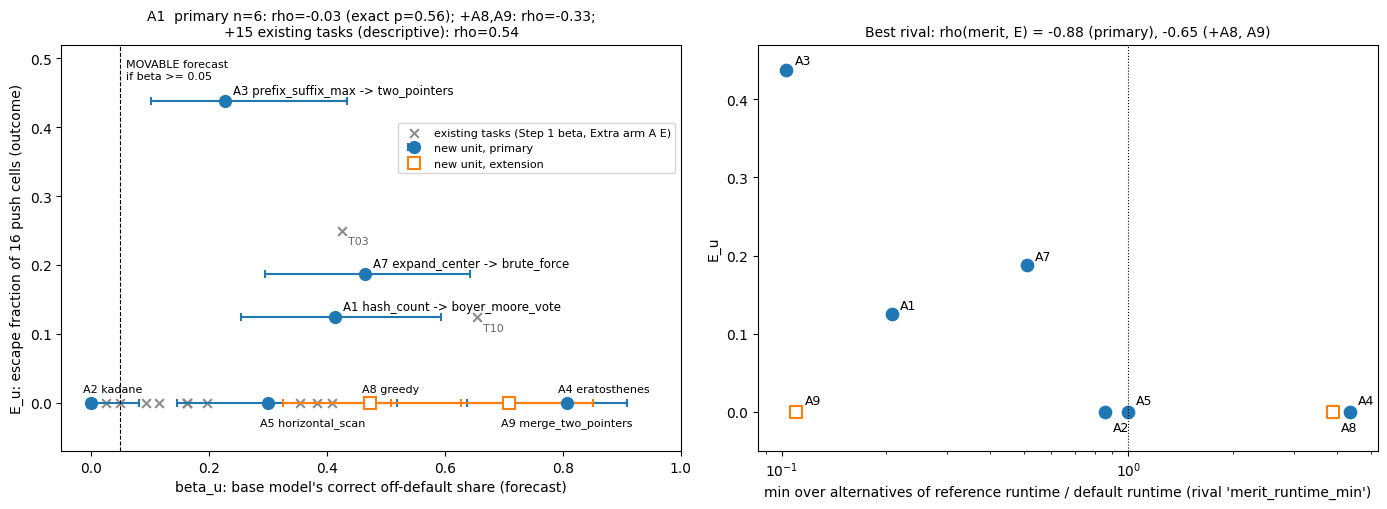

In [24]:
# notebook: new cell, figure 1
a1_units = dict(zip(a1x["units"], zip(a1x["beta"], a1x["E"])))
merit = dict(zip(a1x["units"], a1x["rivals"]["merit_runtime_min"]["values"]))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
ax = axes[0]
ex_rows = [r for r in hs["rows"] if r["kind"] == "existing"]
ax.scatter([r["beta"] for r in ex_rows], [r["E"] for r in ex_rows], marker="x", c="0.55", s=40,
           label="existing tasks (Step 1 beta, Extra arm A E)")
for r in ex_rows:
    if r["E"] > 0:
        ax.annotate(r["unit"], (r["beta"], r["E"]), xytext=(4, -10), textcoords="offset points", fontsize=8, color="0.4")
# labels of units that never escaped alternate above / below the axis line so they do not overlap
zero = sorted((s["prediction"]["beta"], u) for u, s in summ.items() if "prediction" in s and not s["outcome"]["E"])
yoff = {u: (8 if k % 2 == 0 else -16) for k, (_, u) in enumerate(zero)}
for u, s in summ.items():
    if "prediction" not in s:
        continue
    b, ci, E = s["prediction"]["beta"], s["prediction"]["beta_ci"], s["outcome"]["E"]
    prim = u in NEW_UNITS
    ax.errorbar(b, E, xerr=[[b - ci[0]], [ci[1] - b]], fmt="o" if prim else "s", ms=8, capsize=3,
                color="C0" if prim else "C1", mfc="C0" if prim else "white", mew=1.5,
                label=("new unit, primary" if u == "A1" else "new unit, extension" if u == "A8" else None))
    if E:
        ax.annotate(f"{u} {s['prediction']['default']} -> {s['outcome']['landing']}", (b, E), xytext=(6, 5),
                    textcoords="offset points", fontsize=8.5)
    else:
        ax.annotate(f"{u} {s['prediction']['default']}", (b, E), xytext=(-6, yoff[u]), textcoords="offset points",
                    fontsize=8)
ax.axvline(BETA_MOVABLE, ls="--", c="k", lw=0.8)
ax.text(BETA_MOVABLE + 0.01, 0.47, "MOVABLE forecast\nif beta >= 0.05", fontsize=8)
ax.set_xlabel("beta_u: base model's correct off-default share (forecast)")
ax.set_ylabel("E_u: escape fraction of 16 push cells (outcome)")
ax.set_title(f"A1  primary n={a1['n_units']}: rho={a1['rho_beta_E']:.2f} (exact p={a1['perm_p_one_sided']:.2f}); "
             f"+A8,A9: rho={a1x['rho_beta_E']:.2f};\n+15 existing tasks (descriptive): rho={hs['all']['rho_beta_E']:.2f}",
             fontsize=10)
ax.set_xlim(-0.05, 1.0)
ax.set_ylim(-0.07, 0.52)
ax.legend(loc="upper right", bbox_to_anchor=(1.0, 0.82), fontsize=8)

ax = axes[1]
zero_m = sorted((merit[u], u) for u, (b, E) in a1_units.items() if not E)
yoff_m = {u: (6 if k % 2 == 0 else -14) for k, (_, u) in enumerate(zero_m)}
for u, (b, E) in a1_units.items():
    prim = u in NEW_UNITS
    ax.scatter(merit[u], E, s=70, marker="o" if prim else "s", c="C0" if prim else "white",
               edgecolors="C0" if prim else "C1", linewidths=1.5)
    ax.annotate(u, (merit[u], E), xytext=(6, 4 if E else yoff_m[u]), textcoords="offset points", fontsize=9)
ax.set_ylim(-0.05, 0.47)
ax.axvline(1.0, ls=":", c="k", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel("min over alternatives of reference runtime / default runtime (rival 'merit_runtime_min')")
ax.set_ylabel("E_u")
ax.set_title(f"Best rival: rho(merit, E) = {a1['rivals']['merit_runtime_min']['rho_r_E']:.2f} (primary), "
             f"{a1x['rivals']['merit_runtime_min']['rho_r_E']:.2f} (+A8, A9)", fontsize=10)
plt.tight_layout()
plt.show()

### 13d. Which directions move which task?

Each row is a unit or task and each column a push cell (8 fixed directions × α = 1, 2). The colour is the screen
excess, the off-default share of the first 10 rows minus the twin's. **C** = confirmed escape (30 rows + binomial
test); **s** = passed the screen but failed confirmation. Escapes are rare and depend on the direction. A few
directions move several tasks, and most cells move nothing.

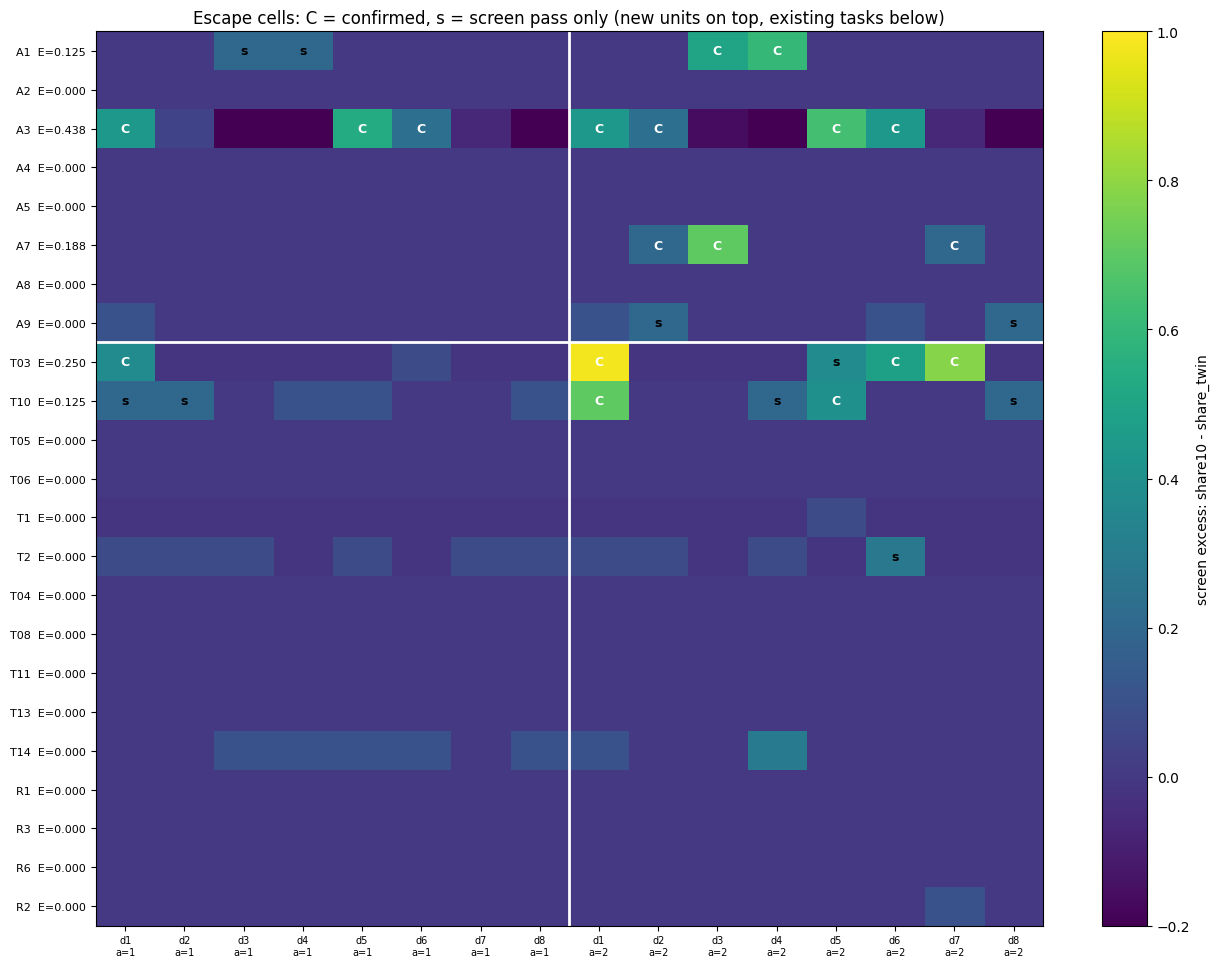

In [25]:
# notebook: new cell, figure 2 (escape table of every unit and existing task)
cells_of = {u: s["escape_cells"] for u, s in summ.items() if "escape_cells" in s}
cells_of.update({t: v["cells"] for t, v in xa.items()})
tasks = list(cells_of)
cols = [(sd, a) for a in ALPHAS for sd in ESC_SEEDS]
M = np.full((len(tasks), len(cols)), np.nan)
fig, ax = plt.subplots(figsize=(13, 0.36 * len(tasks) + 1.5))
for i, t in enumerate(tasks):
    for c in cells_of[t]:
        j = cols.index((c["seed"], c["alpha"]))
        M[i, j] = c["excess10"] if c["excess10"] is not None else np.nan
        mark = "C" if c["confirmed"] else ("s" if c["screen_pass"] else "")
        if mark:
            ax.text(j, i, mark, ha="center", va="center", fontsize=9, fontweight="bold",
                    color="white" if mark == "C" else "black")
im = ax.imshow(M, cmap="viridis", vmin=-0.2, vmax=1.0, aspect="auto")
ax.set_yticks(range(len(tasks)), [f"{t}  E={cells_E:.3f}" for t, cells_E in
                                  ((t, summ[t]["outcome"]["E"] if t in summ else xa[t]["E"]) for t in tasks)], fontsize=8)
ax.set_xticks(range(len(cols)), [f"d{sd - 95100}\na={a:g}" for sd, a in cols], fontsize=7)
ax.axvline(len(ESC_SEEDS) - 0.5, c="w", lw=2)
ax.axhline(sum(1 for t in tasks if t in summ) - 0.5, c="w", lw=2)
plt.colorbar(im, ax=ax, label="screen excess: share10 - share_twin")
ax.set_title("Escape cells: C = confirmed, s = screen pass only (new units on top, existing tasks below)")
plt.tight_layout()
plt.show()

### 13e. Claim A2: where do pushed tasks land?

For each event (forecast MOVABLE and observed movable) the plot shows the three committed forecasts of the landing
distribution over the non-default algorithms, all passed through the same mixture q. They are the base model's
composition, the association answers (corrected mapping, POST HOC) and AST proximity. Black bars are the realised
correct escape programs. The log score is the mean log q of the realised labels; higher is better.

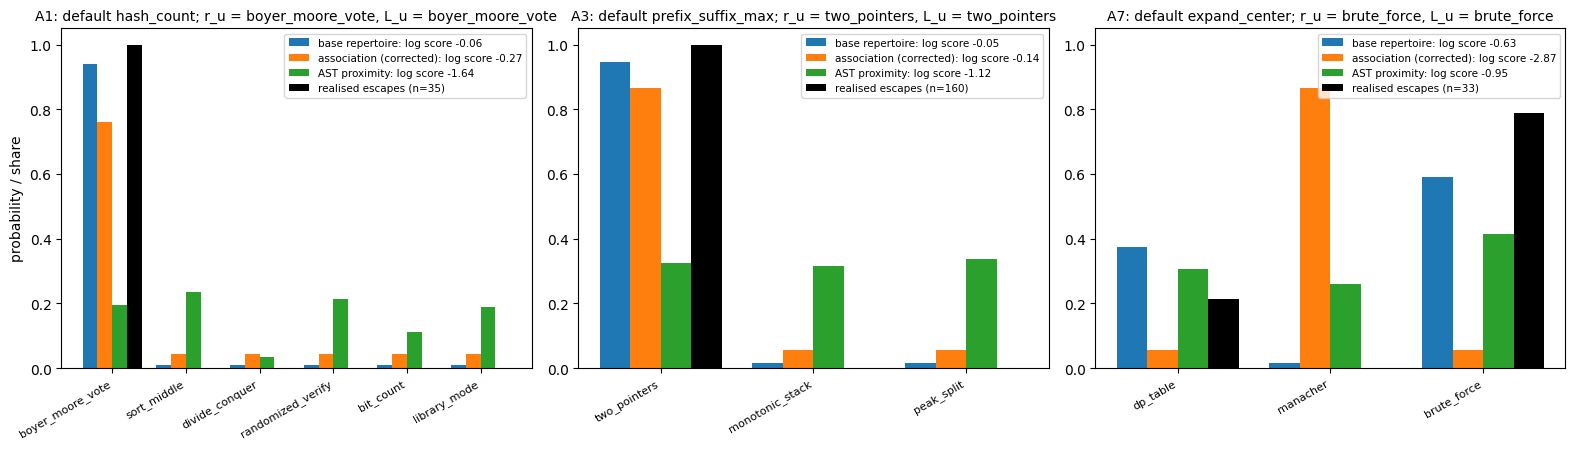

hits 3/3 (Poisson-binomial p = 0.019); mean margin base - corrected association = 0.85 nats, base - proximity = 0.99 nats


In [26]:
# notebook: new cell, figure 3 (forecast distributions vs. realised landings; the same inputs as a2_analysis)
assoc_c = read_json(RESULTS / "assoc_corrected.json")["units"]
ev_units = [e["unit"] for e in a2c["events"]]
fig, axes = plt.subplots(1, len(ev_units), figsize=(5.3 * len(ev_units), 4.6), squeeze=False)
for ax, ev in zip(axes[0], a2c["events"]):
    u = ev["unit"]
    pr = read_json(PRED / f"unit_{u}.json")
    surv = [m for m in pr["catalogue"] if m != pr["default"]]
    real = Counter()
    for c in summ[u]["escape_cells"]:
        if c["confirmed"]:
            real.update(c["landing_counts"])
    pdist = pr["rivals"]["prox_dist"]
    med = float(np.median([pdist[s] for s in surv]))
    qs = {"base repertoire": mixture_q({s: float(pr["base_chat"]["comp_correct"].get(s, 0)) for s in surv}, surv),
          "association (corrected)": mixture_q({s: assoc_c[u]["corrected_counts"].get(s, 0) + 1 for s in surv}, surv),
          "AST proximity": mixture_q({s: math.exp(-pdist[s] / med) for s in surv}, surv)}
    x, w = np.arange(len(surv)), 0.2
    for k, (name, q) in enumerate(qs.items()):
        key = {"base repertoire": "base", "association (corrected)": "assoc", "AST proximity": "prox"}[name]
        ax.bar(x + (k - 1.5) * w, [q[s] for s in surv], w, label=f"{name}: log score {ev['log_scores'][key]:.2f}")
    n_real = sum(real.values())
    ax.bar(x + 1.5 * w, [real.get(s, 0) / n_real for s in surv], w, color="k", label=f"realised escapes (n={n_real})")
    ax.set_xticks(x, surv, rotation=30, ha="right", fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.set_title(f"{u}: default {pr['default']}; r_u = {ev['r']}, L_u = {ev['L']}", fontsize=10)
    ax.legend(fontsize=7.5, loc="upper right")
axes[0][0].set_ylabel("probability / share")
plt.tight_layout()
plt.show()
print(f"hits {a2c['hits']}/{a2c['n_events']} (Poisson-binomial p = {a2c['p_poisson_binomial']:.3f}); "
      f"mean margin base - corrected association = {a2c['base_minus_assoc']['mean']:.2f} nats, "
      f"base - proximity = {a2c['base_minus_prox']['mean']:.2f} nats")

### 13f. Which knob changes the algorithm? Temperature, a novelty instruction, plan noise, or the base model

The off-default share of valid programs per arm. **TWIN** is the instruct model at temperature 1.0. **T1.3** is
temperature 1.3. **NOVELTY** adds "Write a novel algorithm for this task, one you have not seen before."
**PN_a1 / PN_a2** use a fresh random push direction per row. **BASE** and **PLAINC** are Qwen3-8B-Base with the chat
template and as plain completion. Temperature 1.3 changes almost nothing; only A7 moves, by 0.06. The novelty
instruction moves two units, A5 and A9, by 0.2–0.27, and lowers A3. Plan noise moves a few units, by up to 0.22. The
base model writes a non-default algorithm in 0.16–0.74 of its valid programs on every unit except A2, maximum block
sum, where it is collapsed on Kadane's algorithm like the instruct model.

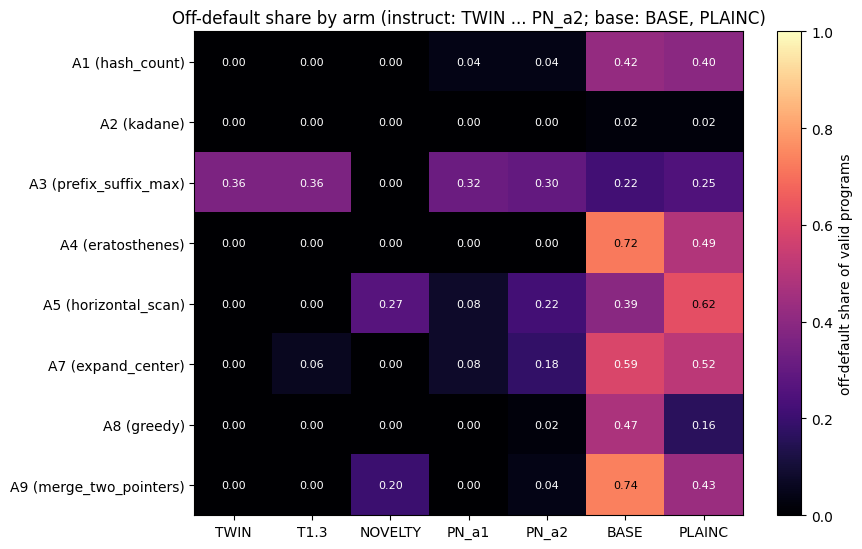

,TWIN,T1.3,NOVELTY,PN_a1,PN_a2,BASE,PLAINC
Hill-1 diversity of correct programs,,,,,,,
A1,1.00,1.00,1.00,1.18,1.17,1.97,2.47
A2,1.00,1.00,1.00,1.00,1.00,1.00,1.00
A3,1.91,1.91,1.00,1.86,1.83,1.71,2.75
A4,1.00,1.00,1.00,1.00,1.00,1.63,1.98
A5,1.00,1.00,1.98,1.32,1.69,2.11,1.54
A7,1.00,1.25,1.00,1.31,1.59,2.71,1.00
A8,1.00,1.00,1.00,1.00,1.00,1.93,1.82
A9,1.00,1.00,1.00,1.00,1.17,2.14,1.57


In [27]:
# notebook: new cell, figure 4 (knob rows: off-default share per arm, all committed units)
kr = read_json(RESULTS / "knob_rows_with_extension.json")
arms = ["TWIN", "T1.3", "NOVELTY", "PN_a1", "PN_a2", "BASE", "PLAINC"]
ku = list(kr)
K = np.array([[kr[u].get(a, {}).get("off_default_share", np.nan) if kr[u].get(a) else np.nan for a in arms] for u in ku],
             dtype=float)
fig, ax = plt.subplots(figsize=(9, 0.5 * len(ku) + 1.6))
im = ax.imshow(K, cmap="magma", vmin=0, vmax=1, aspect="auto")
for i in range(len(ku)):
    for j in range(len(arms)):
        if K[i, j] == K[i, j]:
            ax.text(j, i, f"{K[i, j]:.2f}", ha="center", va="center", fontsize=8, color="w" if K[i, j] < 0.6 else "k")
ax.set_xticks(range(len(arms)), arms)
ax.set_yticks(range(len(ku)), [f"{u} ({summ[u]['prediction']['default']})" for u in ku])
plt.colorbar(im, ax=ax, label="off-default share of valid programs")
ax.set_title("Off-default share by arm (instruct: TWIN ... PN_a2; base: BASE, PLAINC)")
plt.tight_layout()
plt.show()
display(pd.DataFrame({u: {a: kr[u][a]["hill1_correct"] for a in arms if kr[u].get(a)} for u in ku}).T.round(2)
        .rename_axis("Hill-1 diversity of correct programs"))

### 13g. What a push changes in the program

Unit A1 (majority element), shown as three programs from the demo data. The first is the instruct twin's default (a
hash-map count). The second is the base model's runner-up r_u. The third comes from a confirmed escape cell under a
ban-free push, and it uses that same algorithm (Boyer–Moore vote). The novelty audit found **no new algorithm** among
the 6,854 correct programs of the run: a push changes *which known algorithm* is written, not whether a new one
appears.

In [28]:
# notebook: new cell, example programs (display only)
ex_a1 = next(e for e in data["examples"] if e["task"] == "A1")
for prog in ex_a1["example_programs"]:
    print(f"----- {prog['role']}: {prog['label']}   ({prog['model']} model, arm {prog['arm']}, {prog['sample_id']})")
    print(prog["code"].rstrip())
    print()

----- twin default: hash_count   (instruct model, arm TWIN, A1|TWIN|instruct|W1|0)
def solve(nums):
    count = {}
    for num in nums:
        count[num] = count.get(num, 0) + 1
        if count[num] > len(nums) // 2:
            return num

----- base runner-up r_u: boyer_moore_vote   (base model, arm BASE, A1|BASE|base|W1|13)
def solve(nums): 
    '''Returns the value that appears more than len(nums)/2 times in the list nums.'''
    cadidat, count = None, 0
    for n in nums: 
        if not count:
            cadidat, count = n, 1
        elif n == cadidat:
            count += 1
        else:
            count -= 1
    return cadidat

----- confirmed escape, landing L_u: boyer_moore_vote   (instruct model, arm ESC_d95103_a2.0, A1|ESC_d95103_a2.0|instruct|W1|1)
def solve(nums):
    count = 0
    candidate = None
    for num in nums:
        if count == 0:
            candidate = num
        if num == candidate:
            count += 1
        else:
            count -= 1
    return 

## Takeaways

* **A1 (whether a task moves): not supported in this panel.** Across the 6 primary units, β does not rank E
  (ρ ≈ −0.03). The one base-collapsed unit (A2, maximum block sum, β = 0) is immovable, as A1 predicts. But 2 of
  the 5 base-diverse units never escape, including count primes (β = 0.81). The extension units A8 and A9 add two
  more such counter-examples. A trivial rival does far better: E tracks whether an alternative is about **twice as
  fast** as the default (ρ = −0.88).
* **A2 (where a pushed task lands): supported.** On all 3 units that moved (A1, A3, A7), the push landed exactly on
  the base model's most frequent non-default algorithm (3/3, p = 0.019). The base composition beats AST proximity and,
  after the POST HOC fix, the association prompt on log score. No push produced an algorithm outside the base
  repertoire.
* **For the creativity question:** temperature and a "be novel" instruction barely change *which* algorithm the
  instruct model writes. Pushes in activation space move some tasks, and when they do, they move them to an
  alternative the base model already had. They do not reach anything new.

To re-run the GPU stages (sampling, pushes, labelling) see the artifact's `reproducibility.md`. A 24 GB GPU,
`Qwen/Qwen3-8B` and `Qwen/Qwen3-8B-Base`, and OpenRouter keys for the judges are needed. The judge verdicts are cached.